# 21 · Bayesçi ve Olasılıksal Modeller (Bayesian Linear/Logistic Regression, MCMC, Gaussian Process)

> **Bu notebook'ta ne öğreneceğiz?**
> Şimdiye kadar modeller **tek bir parametre vektörü** üretti ($\hat{\mathbf{w}}$) ve belirsizliği sonradan (CI, bootstrap, kalibrasyon) eklemeye çalıştık. Bayesçi yaklaşım ise
> baştan şunu söyler: **parametreler de belirsizdir; onlara bir olasılık dağılımı atayalım, veri geldikçe güncelleyelim.** Sonuç yalnızca "tahmin" değil,
> **tahminin ne kadar güvenilir olduğunu** da veren bir **dağılım**dır. Bu notebook'ta dört şeyi **sıfırdan yazıp** kütüphanelerle doğrulayacağız:
>
> 1. **Bayes kuralı ve eşlenik (conjugate) örnek:** Beta–Binom — posterior kapalı formda; bunu bir **Metropolis–Hastings** örnekleyicisiyle de kurup birebir karşılaştıracağız.
> 2. **Bayesçi Doğrusal Regresyon:** Gauss prior + Gauss olabilirlik = Gauss posterior (kapalı form). Ridge ile bağlantı, **kanıt (evidence) maksimizasyonu** ile ceza katsayısını veriden öğrenme (`sklearn.BayesianRidge` ile birebir), polinom derecesini **marjinal olabilirlikle** seçme (Occam usturası).
> 3. **Bayesçi Lojistik Regresyon:** Eşlenik yok → **Laplace yaklaşımı** (MAP + Hessian) ve **MCMC** (rastgele yürüyüşlü Metropolis, R-hat/ESS tanıları); küçük veride Laplace'ın nerede yetersiz kaldığı ve MLE'ye göre öngörü farkı.
> 4. **Gaussian Process (GP) regresyonu:** Fonksiyonlar üzerinde prior; çekirdek (kernel) seçimi, marjinal olabilirlikle hiperparametre öğrenimi, `sklearn.GaussianProcessRegressor` ile birebir; **Mauna Loa CO₂** serisinde bileşik çekirdek, aradeğerleme ve **öngörünün nerede çöktüğü**; ve GP'nin **Bayesçi optimizasyon** (13'teki Optuna/TPE'nin kardeşi) olarak kullanımı.
>
> **Önkoşul:** 02/04 · Doğrusal regresyon & Ridge (ceza = prior), 03 · Lojistik regresyon, 06 · Naive Bayes (Bayes kuralı), 10-13 · Değerlendirme/kalibrasyon ve hiperparametre optimizasyonu, 01 · olasılık (koşullu, Gauss).
>
> **Veri (hepsi serinin önceki notebook'larında kullanılmadı):**
> - `Howell1` — Dobe !Kung halkının nüfus sayımı (Nancy Howell, 1960'lar; McElreath *Statistical Rethinking*): 544 kişi, boy–kilo–yaş–cinsiyet. Bayesçi doğrusal regresyon ve polinom derecesi seçimi.
> - `Wells` — Bangladeş'te arsenik kirliliği (Gelman & Hill): 3.020 hane, "güvenli kuyuya geçti mi?" (`switch`), arsenik düzeyi, mesafe, eğitim. Bayesçi lojistik regresyon, MCMC.
> - `mcycle` — motosiklet çarpma simülasyonunda baş ivmesi (Silverman 1985; `MASS`): 133 ölçüm, gürültüsü zamana göre değişen klasik GP/yumuşatma örneği.
> - `Mauna Loa CO₂` — NOAA Global Monitoring Laboratory aylık atmosferik CO₂ (1958–2026, 822 ay); Rasmussen & Williams'ın GP kitabındaki klasik örnek.
>
> **Araçlar:** `numpy`/`scipy` (sıfırdan), `sklearn` (`BayesianRidge`, `GaussianProcessRegressor`, `LogisticRegression`), `statsmodels` (MLE karşılaştırması), R (`rstanarm`), DuckDB (SQL).

## 1 · Bayes Kuralı, Eşlenik Prior ve "Neden Dağılım?"

$$
\underbrace{p(\boldsymbol\theta\mid\mathcal{D})}_{\text{posterior}}=\frac{\overbrace{p(\mathcal{D}\mid\boldsymbol\theta)}^{\text{olabilirlik}}\;\overbrace{p(\boldsymbol\theta)}^{\text{prior}}}{\underbrace{p(\mathcal{D})}_{\text{kanıt (evidence)}}},\qquad
p(\mathcal{D})=\int p(\mathcal{D}\mid\boldsymbol\theta)\,p(\boldsymbol\theta)\,d\boldsymbol\theta .
$$

- **MLE**: $\arg\max_\theta p(\mathcal{D}\mid\theta)$ — prior yok. **MAP**: $\arg\max_\theta p(\theta\mid\mathcal{D})$ — posterior'un tepesi (Ridge/Lasso'daki ceza = log-prior). **Tam Bayes**: tepe değil, **tüm dağılım**; tahmin ona göre ortalama alır:
$$p(y^\ast\mid x^\ast,\mathcal{D})=\int p(y^\ast\mid x^\ast,\boldsymbol\theta)\,p(\boldsymbol\theta\mid\mathcal{D})\,d\boldsymbol\theta\quad\text{(posterior öngörü dağılımı)}.$$
- **Güvenilir aralık (credible interval)**: "parametre %90 olasılıkla bu aralıkta" (veri verildiğinde). Güven aralığı (CI) ise "bu prosedür tekrarlansa aralıkların %90'ı gerçeği içerir" — farklı bir ifade; çoğu zaman sayıları benzerdir ama anlamları değil.
- **Eşlenik (conjugate) prior:** posterior, prior ile **aynı aileden** olur → kapalı form. Beta–Binom, Gauss–Gauss, Gamma–Poisson klasik çiftlerdir.

### 🔍 Somut örnek — Beta–Binom (bozuk para): prior Beta(2,2), 10 atışta 7 yazı

Prior Beta(2,2): "para yaklaşık adil, ama kesin değil" (ortalama 0,5). Olabilirlik: $\theta^7(1-\theta)^3$. Çarpım **Beta($2+7,\,2+3$) = Beta(9, 5)**'tir (sayaçlar toplanır):

- **posterior ortalaması** $=9/14=\mathbf{0{,}643}$ (MLE $7/10=0{,}70$'ten prior'a doğru **çekildi**; MAP $=(9-1)/(9+5-2)=8/12=\mathbf{0{,}667}$),
- **posterior std** $=\sqrt{\dfrac{9\cdot5}{14^2\cdot15}}=\mathbf{0{,}124}$; $P(\theta>0{,}5\mid\mathcal{D})\approx\mathbf{0{,}87}$ — "para yazıya meyilli" için ancak **%87** kanıt, MLE'nin verdiği kesinlik hissi yok.
- **öngörü:** bir sonraki atışın yazı olma olasılığı $=\mathbb{E}[\theta\mid\mathcal{D}]=9/14=0{,}643$.

Veri arttıkça (ör. 100 atışta 70 yazı) posterior $\text{Beta}(72,32)$ olur: ortalama $0{,}692$, std $0{,}045$ — prior'un etkisi **otomatik olarak** eriyip veri baskın hale gelir.

### Posterior kapalı formda yoksa: MCMC

**Metropolis–Hastings:** hedef $\pi(\theta)\propto p(\mathcal{D}\mid\theta)p(\theta)$ (**normalizasyon sabiti gerekmez** — evidence'a ihtiyacımız yok!). Mevcut $\theta$'dan $\theta'\sim q(\cdot\mid\theta)$ öner; kabul olasılığı
$$\alpha=\min\!\Big(1,\ \frac{\pi(\theta')\,q(\theta\mid\theta')}{\pi(\theta)\,q(\theta'\mid\theta)}\Big).$$
Simetrik (rastgele yürüyüş) öneride $q$'lar sadeleşir: $\alpha=\min(1,\pi(\theta')/\pi(\theta))$. Zincir uzun koşulursa örnekler $\pi$'den gelir. **Tanılar:** (i) **kabul oranı** (çok yüksek = adımlar çok küçük, çok düşük = çok büyük; çok boyutlu rastgele yürüyüşte yaklaşık %20–30 hedeflenir), (ii) **birden çok zincirle $\hat R$** (Gelman–Rubin; $<1{,}01$ iyi), (iii) **etkin örnek sayısı (ESS)** (otokorelasyon yüzünden $N$ örnek, $N_{\text{eff}}<N$ bağımsız örnek değerindedir).

## 2 · Bayesçi Doğrusal Regresyon (Gauss–Gauss, kapalı form)

Model: $y=\mathbf{w}^\top\boldsymbol\phi(x)+\varepsilon$, $\ \varepsilon\sim\mathcal{N}(0,\beta^{-1})$ ($\beta$: **gürültü kesinliği** $=1/\sigma^2$). Prior: $\mathbf{w}\sim\mathcal{N}(\mathbf{0},\alpha^{-1}\mathbf{I})$ ($\alpha$: **ağırlık kesinliği**). Posterior (kapalı):
$$
\boxed{\ \mathbf{S}_N^{-1}=\alpha\mathbf{I}+\beta\boldsymbol\Phi^\top\boldsymbol\Phi,\qquad \mathbf{m}_N=\beta\,\mathbf{S}_N\boldsymbol\Phi^\top\mathbf{y}\ }
\qquad\Rightarrow\qquad \mathbf{w}\mid\mathcal{D}\sim\mathcal{N}(\mathbf{m}_N,\mathbf{S}_N).
$$
**Öngörü dağılımı:** $\ p(y^\ast\mid x^\ast,\mathcal{D})=\mathcal{N}\!\big(\mathbf{m}_N^\top\boldsymbol\phi^\ast,\ \ \underbrace{\beta^{-1}}_{\text{veri gürültüsü}}+\underbrace{\boldsymbol\phi^{\ast\top}\mathbf{S}_N\boldsymbol\phi^\ast}_{\text{parametre belirsizliği}}\big)$ — ikinci terim **veriden uzaklaştıkça büyür** (extrapolation'da belirsizlik artar).

**Ridge ile bağlantı:** $\mathbf{m}_N=\arg\min\ \tfrac{\beta}{2}\|\mathbf{y}-\boldsymbol\Phi\mathbf{w}\|^2+\tfrac{\alpha}{2}\|\mathbf{w}\|^2$, yani **Ridge**, $\lambda=\alpha/\beta$ ile. Ridge size $\mathbf{m}_N$'yi verir; Bayesçi yaklaşım ek olarak **$\mathbf{S}_N$** (parametre belirsizliği) ve **öngörü varyansını** verir.

### 🔍 Somut örnek — 3 nokta, $\alpha=\beta=1$

Noktalar: $(x,y)=(-1,-0{,}5),\ (0,0{,}5),\ (1,1{,}5)$; $\boldsymbol\phi=[1,x]$ (kesişim + eğim).

- $\boldsymbol\Phi^\top\boldsymbol\Phi=\begin{pmatrix}3&0\\0&2\end{pmatrix}\Rightarrow\mathbf{S}_N^{-1}=\begin{pmatrix}4&0\\0&3\end{pmatrix},\ \mathbf{S}_N=\mathrm{diag}(0{,}25,\ 0{,}333)$.
- $\boldsymbol\Phi^\top\mathbf{y}=[\sum y,\ \sum xy]=[1{,}5,\ 2{,}0]\Rightarrow\mathbf{m}_N=[1{,}5/4,\ 2/3]=\mathbf{[0{,}375,\ 0{,}667]}$. OLS ise $[0{,}5,\ 1{,}0]$ verirdi: prior katsayıları **sıfıra çekti** (shrinkage). Eğim, daha az bilgi taşıdığı için ($\boldsymbol\Phi^\top\boldsymbol\Phi$ köşegeni 2, kesişim için 3) kesişimden daha çok çekildi (çarpan $\tfrac{2}{2+1}=\tfrac23$ vs $\tfrac{3}{3+1}=\tfrac34$).
- **Öngörü** $x^\ast=0$: ortalama $0{,}375$; $\boldsymbol\phi^{\ast\top}\mathbf{S}_N\boldsymbol\phi^\ast=0{,}25$ → toplam varyans $1+0{,}25=1{,}25$ (sd $1{,}118$).
- **Öngörü** $x^\ast=2$ (veri dışı): ortalama $0{,}375+2\cdot0{,}667=1{,}708$; $\boldsymbol\phi^{\ast\top}\mathbf{S}_N\boldsymbol\phi^\ast=0{,}25+4\cdot0{,}333=1{,}583$ → toplam varyans $2{,}583$ (sd $1{,}607$). **Veriden uzaklaşınca belirsizlik büyüdü**: bu, nokta tahminli bir modelin göstermediği bilgidir.

**Kanıt (evidence) maksimizasyonu (Tipping/MacKay):** $\alpha,\beta$'yı elle ayarlamak yerine marjinal olabilirliği $p(\mathbf{y}\mid\alpha,\beta)=\int p(\mathbf{y}\mid\mathbf{w},\beta)p(\mathbf{w}\mid\alpha)d\mathbf{w}$ enbüyütürüz (kapalı formda log kanıt vardır). Sabit-nokta güncellemeleri:
$$\gamma=\sum_i\frac{\lambda_i}{\alpha+\lambda_i}\ \ (\lambda_i:\ \beta\boldsymbol\Phi^\top\boldsymbol\Phi\text{'nin özdeğerleri}),\qquad \alpha\leftarrow\frac{\gamma}{\mathbf{m}_N^\top\mathbf{m}_N},\qquad \beta^{-1}\leftarrow\frac{\|\mathbf{y}-\boldsymbol\Phi\mathbf{m}_N\|^2}{N-\gamma}.$$
$\gamma$ "etkin parametre sayısı"dır (verinin belirlediği yön sayısı). Çapraz doğrulamaya gerek kalmadan ceza öğrenilir. **Bayesçi Occam usturası:** marjinal olabilirlik, çok esnek modelleri (veriyi açıklayabileceği geniş bir parametre uzayına prior kütlesi dağıttığı için) otomatik **cezalandırır**; polinom derecesini kanıtla seçebiliriz.

## 3 · Bayesçi Lojistik Regresyon: Laplace Yaklaşımı ve MCMC

$y_i\in\{0,1\}$, $p_i=\sigma(\mathbf{w}^\top\mathbf{x}_i)$, prior $\mathbf{w}\sim\mathcal{N}(\mathbf{0},\alpha^{-1}\mathbf{I})$. **Eşlenik yok** (sigmoid–Gauss çarpımı Gauss değil) → posterior $\propto \exp\!\big(\sum_i[y_i z_i-\log(1+e^{z_i})]-\tfrac{\alpha}{2}\|\mathbf{w}\|^2\big)$ kapalı değil.

**Laplace yaklaşımı:** log-posterior'un tepesinde ikinci dereceden Taylor açılımı → Gauss:
$$\mathbf{w}\mid\mathcal{D}\approx\mathcal{N}\big(\mathbf{w}_{\text{MAP}},\ \mathbf{H}^{-1}\big),\quad \mathbf{H}=\boldsymbol\Phi^\top\mathbf{R}\boldsymbol\Phi+\alpha\mathbf{I},\ \ \mathbf{R}=\mathrm{diag}\big(p_i(1-p_i)\big).$$
$\mathbf{w}_{\text{MAP}}$ **Newton–IRLS** ile bulunur: $\mathbf{w}\leftarrow\mathbf{w}+\mathbf{H}^{-1}\mathbf{g}$, $\ \mathbf{g}=\boldsymbol\Phi^\top(\mathbf{y}-\mathbf{p})-\alpha\mathbf{w}$ (lojistik regresyonun bildiğimiz IRLS'i + ridge terimi).

**Öngörü:** $\mu=\mathbf{w}_{\text{MAP}}^\top\mathbf{x}^\ast$, $\ \sigma^2=\mathbf{x}^{\ast\top}\mathbf{H}^{-1}\mathbf{x}^\ast$. Sigmoid'in Gauss üzerinden integrali kapalı değildir; **probit yaklaşımı**: $\ p(y^\ast=1\mid\mathbf{x}^\ast)\approx\sigma\!\big(\kappa(\sigma^2)\,\mu\big),\ \ \kappa=(1+\pi\sigma^2/8)^{-1/2}$ — belirsizlik arttıkça olasılık $0{,}5$'e **çekilir** (MAP'ın aşırı özgüvenli kalibrasyon hatasını düzeltir). MCMC ise posterior örneklerinin ortalamasıyla aynı integrali doğrudan yaklaşıklar.

### 🔍 Somut örnek — tek parametreli lojistik, ilk Newton adımı (elle)

Veri: $x=(-1,\,1,\,2)$, $y=(0,\,1,\,1)$, $\alpha=1$, kesişim yok, başlangıç $w=0$ ($p_i=0{,}5$ hepsi için).

- Gradyan: $g=\sum(y_i-p_i)x_i-\alpha w=(0-0{,}5)(-1)+(1-0{,}5)(1)+(1-0{,}5)(2)=0{,}5+0{,}5+1=\mathbf{2{,}0}$.
- Hessian: $H=\sum p_i(1-p_i)x_i^2+\alpha=0{,}25\,(1+1+4)+1=\mathbf{2{,}5}$.
- Newton adımı: $w_1=0+2{,}0/2{,}5=\mathbf{0{,}8}$. Birkaç adım sonra $w_{\text{MAP}}\approx0{,}880$, $H\approx1{,}915$ → **Laplace sd $=1/\sqrt{H}\approx0{,}72$**: eğimin "yaklaşık $0{,}88\pm0{,}72$" olduğunu söylüyoruz — **3 nokta** çok az bilgi veriyor, sıfır da makul bir değer (z=1,2).

**Laplace ne zaman kötüleşir?** Posterior **çarpıksa veya çok-tepeli** ise (az veri, ayrışabilir sınıflar), tek bir Gauss yetmez. Aşağıda $n=25$ örnekle MCMC ile Laplace'ı **karşılaştıracağız**.

## 4 · Gaussian Process (GP) Regresyonu

Parametrik model yerine **fonksiyonun kendisi** üzerinde bir prior: $f\sim\mathcal{GP}(m,k)$ — **herhangi sonlu sayıda** nokta için $[f(x_1),\dots,f(x_n)]$ ortak Gauss'tur, kovaryansı **çekirdek** $k(x,x')$ verir (yakın girdiler → benzer çıktılar). $m=0$ alırsak, gürültü $\sigma_n^2$ ile ($y=f(x)+\varepsilon$):

$$
\boxed{\ \mu_\ast=\mathbf{k}_\ast^\top\,(\mathbf{K}+\sigma_n^2\mathbf{I})^{-1}\mathbf{y},\qquad
\sigma_\ast^2=k(x_\ast,x_\ast)-\mathbf{k}_\ast^\top(\mathbf{K}+\sigma_n^2\mathbf{I})^{-1}\mathbf{k}_\ast\ }\quad(+\ \sigma_n^2\ \text{gözlem için})
$$

**Hiperparametreler ($\theta$: ölçek $\sigma_f$, uzunluk ölçeği $\ell$, gürültü $\sigma_n$...) marjinal olabilirlikle** öğrenilir:
$$\log p(\mathbf{y}\mid X,\theta)=-\tfrac12\mathbf{y}^\top\mathbf{K}_y^{-1}\mathbf{y}-\tfrac12\log|\mathbf{K}_y|-\tfrac{n}{2}\log2\pi,\quad\mathbf{K}_y=\mathbf{K}+\sigma_n^2\mathbf{I}.$$
İlk terim **uyum**, ikinci terim (log-determinant) **karmaşıklık cezası**dır — yine Bayesçi Occam. Hesaplama **Cholesky** ile $O(n^3)$ zaman, $O(n^2)$ bellek: GP **bin-onbin** noktaya kadar kullanışlıdır.

**Çekirdekler (bileşenlerin toplamı/çarpımı yine geçerli çekirdektir):**

| Çekirdek | $k(r)$, $r=\lvert x-x'\rvert$ | Fonksiyon düzgünlüğü / kullanım |
|---|---|---|
| **RBF (SE)** | $\sigma_f^2\exp\!\big(-r^2/2\ell^2\big)$ | Sonsuz türevlenebilir, çok düzgün |
| **Matérn $\nu$** | $\sigma_f^2\frac{2^{1-\nu}}{\Gamma(\nu)}\big(\tfrac{\sqrt{2\nu}r}{\ell}\big)^\nu K_\nu\big(\tfrac{\sqrt{2\nu}r}{\ell}\big)$ | $\nu=\tfrac32,\tfrac52$: sonlu türevlenebilir, gerçek veriye RBF'den gerçekçi |
| **Periyodik** | $\sigma_f^2\exp\!\big(-2\sin^2(\pi r/p)/\ell^2\big)$ | Mevsimsellik ($p$: periyot) |
| **Rational Quadratic** | $\sigma_f^2\big(1+\tfrac{r^2}{2\alpha\ell^2}\big)^{-\alpha}$ | Farklı ölçeklerde RBF karışımı ($\alpha\to\infty$: RBF) |
| **Doğrusal / polinom** | $\sigma^2(x\,x'+\sigma_0^2)^d$ | **Bayesçi doğrusal regresyonun** GP karşılığı — trend |

### 🔍 Somut örnek — 2 eğitim noktası, RBF($\ell=1,\sigma_f=1$), $\sigma_n^2=0{,}01$

$x=(0,1)$, $y=(0,1)$; $k(0,1)=e^{-1/2}=0{,}6065$. $\mathbf{K}_y=\begin{pmatrix}1{,}01&0{,}6065\\0{,}6065&1{,}01\end{pmatrix}$, $\ \boldsymbol\alpha=\mathbf{K}_y^{-1}\mathbf{y}=[-0{,}930,\ 1{,}549]$.
$x_\ast=0{,}5$: $\mathbf{k}_\ast=[e^{-1/8},e^{-1/8}]=[0{,}8825,\ 0{,}8825]$ →
**ortalama** $\mu_\ast=\mathbf{k}_\ast^\top\boldsymbol\alpha=0{,}8825\,(0{,}619)=\mathbf{0{,}546}$ (iki noktanın ortasında beklenen $\approx0{,}5$'e yakın),
**varyans** $\sigma_\ast^2=1-\mathbf{k}_\ast^\top\mathbf{K}_y^{-1}\mathbf{k}_\ast=1-0{,}9635=\mathbf{0{,}0365}$ (sd $0{,}19$; gözlem gürültüsü dahil $0{,}0465$). Aynı hesap $x_\ast=5$'te (veriden uzak): $\mathbf{k}_\ast\approx0\Rightarrow\mu_\ast\approx0,\ \sigma_\ast^2\approx1$ — **veri yoksa prior'a dönülür** ve belirsizlik maksimumdur.

**Bayesçi optimizasyon (BO)**: pahalı bir $f$'yi (ör. model doğruluğu = hiperparametre fonksiyonu) az sayıda değerlendirmeyle minimize etmek için GP **vekil model** (surrogate) olur; her adımda **edinim (acquisition) fonksiyonu** bir sonraki noktayı seçer. **Expected Improvement** ($f_{\min}$ şimdiye kadarki en iyi, $z=\frac{f_{\min}-\mu(x)-\xi}{\sigma(x)}$):
$$\mathrm{EI}(x)=(f_{\min}-\mu(x)-\xi)\,\Phi(z)+\sigma(x)\,\varphi(z).$$
İlk terim **sömürü** (düşük ortalama), ikinci terim **keşif** (yüksek belirsizlik). 13'teki Optuna'nın TPE'si farklı bir vekil kullanır; fikir aynıdır.

## 5 · Ne Zaman Bayesçi? Özet

| Konu | Frekansçı / nokta tahmin | Bayesçi / olasılıksal |
|---|---|---|
| Çıktı | $\hat{\mathbf{w}}$, sonradan CI/bootstrap | **Posterior dağılım**, öngörü dağılımı |
| Küçük veri | Aşırı uyum, belirsizlik hissi yok | Prior düzenler, geniş posterior **dürüstçe** belirsizliği gösterir |
| Düzenleme (ceza) | $\lambda$ CV ile seçilir | Prior; $\alpha,\beta$ **kanıtla** öğrenilebilir |
| Model seçimi | CV/AIC/BIC | **Marjinal olabilirlik** (Occam otomatik) |
| Ölçeklenebilirlik | Çok iyi | **Yavaş:** MCMC pahalı, GP $O(n^3)$ |
| Risk | Prior'u gizlemek (örtük) | Kötü prior/çekirdek **aşırı özgüven** üretir (aşağıda CO₂ öngörüsünde göreceğiz) |

**Yol haritası:**

| Adım | Ne yapacağız? | Veri |
|---|---|---|
| 1 | Beta–Binom + Metropolis–Hastings, eşlenik cevapla birebir | sentetik/elle |
| 2 | Bayesçi doğrusal regresyon sıfırdan; `BayesianRidge` ile doğrulama; veri boyutu etkisi; kanıtla polinom derecesi | Howell1 |
| 3 | Bayesçi lojistik: Newton-MAP, Laplace, MH (4 zincir, $\hat R$, ESS); küçük veri deneyi; öngörü kalibrasyonu | Wells |
| 4 | GP sıfırdan; `sklearn` ile birebir; çekirdek karşılaştırması; heteroscedastic gürültü uyarısı | mcycle |
| 5 | CO₂: bileşik çekirdek, aradeğerleme vs öngörü, ufuk bazlı kapsama | Mauna Loa |
| 6 | GP + Expected Improvement ile Bayesçi optimizasyon, rastgele aramayla kıyas | sentetik 1B |

# 🐍 Python Uygulaması

Adımlar:
1. **Beta–Binom + Metropolis–Hastings** (sıfırdan): kapalı form posterior ile MCMC birebir; $\hat R$ ve ESS tanıları
2. **Bayesçi doğrusal regresyon** (Howell1): sıfırdan posterior, `BayesianRidge`/`Ridge` ile doğrulama, veri boyutu etkisi, kanıtla polinom derecesi
3. **Bayesçi lojistik regresyon** (Wells): Newton-MAP, Laplace, 4 zincirli MH; küçük veride Laplace vs MCMC; öngörü performansı (MLE vs MAP vs Bayes)
4. **Gaussian Process** (mcycle): sıfırdan GP, `sklearn` ile birebir, çekirdek karşılaştırması, heteroscedastic gürültü uyarısı
5. **Mauna Loa CO₂:** bileşik çekirdek, aradeğerleme vs öngörü, ufuk bazlı kapsama
6. **Bayesçi optimizasyon:** GP + Expected Improvement vs rastgele arama

In [1]:
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.polynomial import legendre as Leg
from scipy import stats, optimize, linalg
from scipy.special import expit

from sklearn.linear_model import BayesianRidge, Ridge, LinearRegression, LogisticRegression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel as C, ExpSineSquared, RationalQuadratic, DotProduct
from sklearn.model_selection import KFold
import statsmodels.api as sm

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RNG = np.random.default_rng(42)

# --- MCMC için ortak araçlar (Adım 1 ve 3'te kullanılır) ---
def metropolis(logpost, x0, n, scale, rng, chol=None):
    """Rastgele yürüyüşlü Metropolis. x0: başlangıç (d,). scale*chol: öneri kovaryansının çarpanı. (zincir (n,d), kabul oranı) döner."""
    x = np.asarray(x0, float).copy(); d = x.size; lp = logpost(x); out = np.empty((n, d)); acc = 0
    L = np.eye(d) if chol is None else chol
    for i in range(n):
        prop = x + scale * (L @ rng.standard_normal(d)); lq = logpost(prop)
        if np.log(rng.random()) < lq - lp:
            x, lp = prop, lq; acc += 1
        out[i] = x
    return out, acc / n

def rhat(chains):
    """Bölünmüş (split) Gelman-Rubin R-hat. chains: (m, n) tek parametre için zincirler."""
    c = np.asarray(chains); m, n = c.shape; h = n // 2
    c = np.concatenate([c[:, :h], c[:, h:2 * h]], axis=0); m, n = c.shape
    W = c.var(axis=1, ddof=1).mean(); B = n * c.mean(axis=1).var(ddof=1)
    return np.sqrt(((n - 1) / n * W + B / n) / W)

def ess(chains):
    """Etkin örnek sayısı (Geyer'in başlangıç-pozitif dizisiyle otokorelasyon toplamı). chains: (m, n)."""
    c = np.asarray(chains); m, n = c.shape
    acov = np.mean([np.correlate(ci - ci.mean(), ci - ci.mean(), 'full')[n - 1:] / n for ci in c], axis=0)
    rho = acov / acov[0]; s = 0.0
    for t in range(1, n - 1, 2):
        pair = rho[t] + rho[t + 1]
        if pair < 0: break
        s += pair
    return m * n / (1 + 2 * s)

## Adım 1 · Beta–Binom ve Metropolis–Hastings

Teori bölümündeki örnek: prior Beta(2,2), 10 atışta 7 yazı. Önce **kapalı form** (Beta(9,5)), sonra aynı posterior'u **kapalı formdan habersiz** bir MH ile üretip karşılaştırıyoruz. Sonda **evidence** (marjinal olabilirlik) ile üç farklı prior'u kıyaslıyoruz.

Posterior Beta(9, 5): ortalama=0.6429  sd=0.1237  MAP=0.6667  MLE=0.70  P(theta>0.5)=0.8666
%90 güvenilir aralık: [0.427, 0.834]
100 atışta 70 yazı: Beta(72, 32), ortalama=0.692, sd=0.045



MH (4 zincir x 18000): ortalama=0.6441  sd=0.1233  kabul oranı(son zincir)=0.50  R-hat=1.0002  ESS=15474 / 72000
  grid yaklaşımı ortalaması: 0.6429 | kapalı form: 0.6429
  MH %5-%95 kantilleri: [0.429, 0.835] | kapalı form: [0.427, 0.834]

Evidence p(D | prior) — hangi prior veriyi daha iyi 'öngördü'?
  düz Beta(1,1)              p(D)=0.0909   posterior ort.=0.667
  ılımlı Beta(2,2)           p(D)=0.1119   posterior ort.=0.643
  adil-inançlı Beta(20,20)   p(D)=0.1233   posterior ort.=0.540
  yanlış-inançlı Beta(2,20)  p(D)=0.0003   posterior ort.=0.281


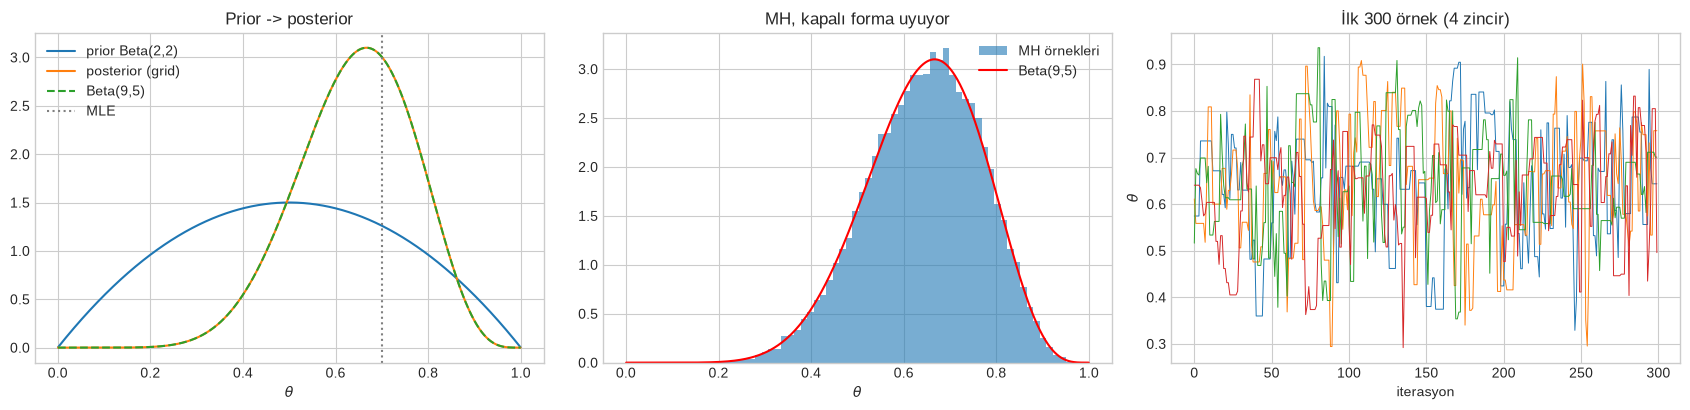

YORUM: Posterior ortalaması (0.643) MLE'den (0.70) prior'a doğru çekildi, sd 0.124: 10 atışla 'yazıya meyilli' demeye ancak %87 kanıt var. MH, evidence'ı hiç bilmeden kapalı formla aynı ortalama/sd/kantilleri verdi.
       Evidence: veriyle çelişen 'yanlış-inançlı' prior'un p(D)'si düşük — marjinal olabilirlik modeli (prior dahil) veriyi öngörme başarısına göre puanlıyor; bu, Adım 2'deki polinom derecesi seçiminin de temeli.


In [2]:
heads, flips = 7, 10
a0, b0 = 2, 2
post = stats.beta(a0 + heads, b0 + flips - heads)                       # eşlenik güncelleme: sayaçlar toplanır
mle = heads / flips; map_ = (post.args[0] - 1) / (sum(post.args) - 2)
print(f"Posterior Beta{post.args}: ortalama={post.mean():.4f}  sd={post.std():.4f}  MAP={map_:.4f}  MLE={mle:.2f}  P(theta>0.5)={1-post.cdf(.5):.4f}")
print(f"%90 güvenilir aralık: [{post.ppf(.05):.3f}, {post.ppf(.95):.3f}]")
post100 = stats.beta(a0 + 70, b0 + 30); print(f"100 atışta 70 yazı: Beta{post100.args}, ortalama={post100.mean():.3f}, sd={post100.std():.3f}")

# grid yaklaşımı (normalizasyon sabitini sayısal integralle bul)
grid = np.linspace(0.0005, 0.9995, 2000)
unnorm = grid ** heads * (1 - grid) ** (flips - heads) * stats.beta(a0, b0).pdf(grid)
grid_post = unnorm / np.trapezoid(unnorm, grid)

# MH: normalizasyon sabiti GEREKMİYOR; theta (0,1) dışına çıkan öneriler reddedilir
def logpost_coin(t):
    th = t[0]
    if th <= 0 or th >= 1: return -np.inf
    return heads * np.log(th) + (flips - heads) * np.log(1 - th) + stats.beta(a0, b0).logpdf(th)

chains = []
for s_ in range(4):
    rng_ = np.random.default_rng(s_); x0 = rng_.uniform(0.05, 0.95)       # dağınık başlangıçlar
    ch, acc = metropolis(logpost_coin, [x0], 20000, 0.25, rng_); chains.append(ch[2000:, 0])   # ilk 2000 = ısınma (burn-in)
chains = np.array(chains); pooled = chains.ravel()
print(f"\nMH (4 zincir x 18000): ortalama={pooled.mean():.4f}  sd={pooled.std():.4f}  kabul oranı(son zincir)={acc:.2f}  R-hat={rhat(chains):.4f}  ESS={ess(chains):.0f} / {pooled.size}")
print(f"  grid yaklaşımı ortalaması: {np.trapezoid(grid*grid_post, grid):.4f} | kapalı form: {post.mean():.4f}")
print(f"  MH %5-%95 kantilleri: [{np.quantile(pooled,.05):.3f}, {np.quantile(pooled,.95):.3f}] | kapalı form: [{post.ppf(.05):.3f}, {post.ppf(.95):.3f}]")

# Evidence = P(7 yazı | prior): Beta-Binom pmf. Prior'a duyarlılık
print("\nEvidence p(D | prior) — hangi prior veriyi daha iyi 'öngördü'?")
for nm, (aa, bb) in {'düz Beta(1,1)': (1, 1), 'ılımlı Beta(2,2)': (2, 2), 'adil-inançlı Beta(20,20)': (20, 20), 'yanlış-inançlı Beta(2,20)': (2, 20)}.items():
    print(f"  {nm:26s} p(D)={stats.betabinom.pmf(heads, flips, aa, bb):.4f}   posterior ort.={(aa+heads)/(aa+bb+flips):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(grid, stats.beta(a0, b0).pdf(grid), label='prior Beta(2,2)'); ax[0].plot(grid, grid_post, label='posterior (grid)'); ax[0].plot(grid, post.pdf(grid), '--', label='Beta(9,5)')
ax[0].axvline(mle, c='gray', ls=':', label='MLE'); ax[0].legend(); ax[0].set(title='Prior -> posterior', xlabel=r'$\theta$')
ax[1].hist(pooled, bins=60, density=True, alpha=.6, label='MH örnekleri'); ax[1].plot(grid, post.pdf(grid), 'r', label='Beta(9,5)'); ax[1].legend(); ax[1].set(title='MH, kapalı forma uyuyor', xlabel=r'$\theta$')
for c_ in chains: ax[2].plot(c_[:300], lw=.7)
ax[2].set(title='İlk 300 örnek (4 zincir)', xlabel='iterasyon', ylabel=r'$\theta$')
plt.tight_layout(); plt.show()
print("YORUM: Posterior ortalaması (0.643) MLE'den (0.70) prior'a doğru çekildi, sd 0.124: 10 atışla 'yazıya meyilli' demeye ancak %87 kanıt var. MH, evidence'ı hiç bilmeden kapalı formla aynı ortalama/sd/kantilleri verdi.")
print("       Evidence: veriyle çelişen 'yanlış-inançlı' prior'un p(D)'si düşük — marjinal olabilirlik modeli (prior dahil) veriyi öngörme başarısına göre puanlıyor; bu, Adım 2'deki polinom derecesi seçiminin de temeli.")

## Adım 2 · Bayesçi Doğrusal Regresyon (Howell1)

Veri: Dobe !Kung nüfus sayımı, 544 kişi. Önce **yetişkinlerde** (yaş ≥ 18, $n=352$) boy ~ kilo: yaklaşık doğrusal. Sınıf `BayesLinReg`: sabit $(\alpha,\beta)$ ile posterior, MacKay güncellemeleriyle **kanıt maksimizasyonu**, öngörü ortalama/sd'si ve **log kanıt**.

In [3]:
class BayesLinReg:
    """Gauss prior (precision alpha) + Gauss gürültü (precision beta) -> kapalı form posterior."""
    def __init__(self, alpha=1.0, beta=1.0): self.alpha, self.beta = alpha, beta
    def posterior(self, Phi, y):
        M = Phi.shape[1]; A = self.alpha * np.eye(M) + self.beta * Phi.T @ Phi
        self.S = np.linalg.inv(A); self.m = self.beta * self.S @ Phi.T @ y; return self
    def fit_evidence(self, Phi, y, iters=5000, tol=1e-12):
        N, M = Phi.shape; lam = np.linalg.eigvalsh(Phi.T @ Phi)
        for _ in range(iters):
            self.posterior(Phi, y); g = np.sum(self.beta * lam / (self.alpha + self.beta * lam))     # etkin parametre sayısı
            a_new = g / (self.m @ self.m); b_new = (N - g) / np.sum((y - Phi @ self.m) ** 2)
            done = abs(a_new - self.alpha) < tol * self.alpha and abs(b_new - self.beta) < tol * self.beta
            self.alpha, self.beta = a_new, b_new
            if done: break
        self.gamma = g; return self.posterior(Phi, y)
    def log_evidence(self, Phi, y):
        N, M = Phi.shape; A = self.alpha * np.eye(M) + self.beta * Phi.T @ Phi; m = self.beta * np.linalg.solve(A, Phi.T @ y)
        E = self.beta / 2 * np.sum((y - Phi @ m) ** 2) + self.alpha / 2 * m @ m
        return M / 2 * np.log(self.alpha) + N / 2 * np.log(self.beta) - E - 0.5 * np.linalg.slogdet(A)[1] - N / 2 * np.log(2 * np.pi)
    def predict(self, Phi, noise=True):
        mean = Phi @ self.m; var = np.einsum('ij,jk,ik->i', Phi, self.S, Phi) + (1 / self.beta if noise else 0.0)
        return mean, np.sqrt(var)

# teori bölümündeki 3 noktalı elle örnek
Phi3 = np.array([[1, -1], [1, 0], [1, 1.]]); y3 = np.array([-.5, .5, 1.5])
b3 = BayesLinReg(1.0, 1.0).posterior(Phi3, y3)
print("Elle örnek: m_N =", b3.m.round(4), "| S_N köşegeni =", np.diag(b3.S).round(4), "| OLS =", np.linalg.lstsq(Phi3, y3, rcond=None)[0])
for xs_ in (0, 2):
    mu_, sd_ = b3.predict(np.array([[1, xs_]])); print(f"  x*={xs_}: ortalama={mu_[0]:.4f}, öngörü sd={sd_[0]:.4f}")

Elle örnek: m_N = [0.375  0.6667] | S_N köşegeni = [0.25   0.3333] | OLS = [0.5 1. ]
  x*=0: ortalama=0.3750, öngörü sd=1.1180
  x*=2: ortalama=1.7083, öngörü sd=1.6073


In [4]:
howell = pd.read_csv('data/howell1.csv', sep=';')
adult = howell[howell.age >= 18].reset_index(drop=True)
print(f"Howell1: {len(howell)} kişi | yetişkin: {len(adult)} | boy ort. {adult.height.mean():.1f} cm, kilo ort. {adult.weight.mean():.1f} kg")
xa, ya = adult.weight.values, adult.height.values
xc, yc = xa - xa.mean(), ya - ya.mean()                    # merkezle: kesişim ~0 olur, ortak prior (alpha) anlamlı kalır
Phi_a = np.c_[np.ones(len(xc)), xc]

be = BayesLinReg(1.0, 1.0).fit_evidence(Phi_a, yc)
br = BayesianRidge(fit_intercept=False, tol=1e-12, max_iter=5000, compute_score=True, alpha_1=0, alpha_2=0, lambda_1=0, lambda_2=0).fit(Phi_a, yc)
print("\n--- Sıfırdan vs sklearn.BayesianRidge (sklearn'de `alpha_` = GÜRÜLTÜ kesinliği (bizim beta), `lambda_` = AĞIRLIK kesinliği (bizim alpha)) ---")
print(f"beta  (gürültü kesinliği): bizim {be.beta:.6f} | sklearn {br.alpha_:.6f}   -> gürültü sd = {1/np.sqrt(be.beta):.3f} cm")
print(f"alpha (ağırlık kesinliği): bizim {be.alpha:.6f} | sklearn {br.lambda_:.6f}")
print(f"posterior ortalaması: bizim {be.m.round(6)} | sklearn {br.coef_.round(6)} | maks. fark {np.abs(be.m - br.coef_).max():.2e}")
print(f"posterior kovaryansı maks. fark (S_N vs sigma_): {np.abs(be.S - br.sigma_).max():.2e}")
print(f"log kanıt: bizim {be.log_evidence(Phi_a, yc):.4f} | sklearn scores_[-1] {br.scores_[-1]:.4f}")
ridge = Ridge(alpha=be.alpha / be.beta, fit_intercept=False).fit(Phi_a, yc)
print(f"Ridge(lambda=alpha/beta={be.alpha/be.beta:.4f}) katsayıları posterior ortalamasıyla aynı mı? maks. fark {np.abs(ridge.coef_ - be.m).max():.2e}")
ols = np.linalg.lstsq(Phi_a, yc, rcond=None)[0]
print(f"OLS: {ols.round(5)} | posterior sd'ler (kesişim, eğim): {np.sqrt(np.diag(be.S)).round(4)} | etkin parametre sayısı gamma={be.gamma:.3f}")
print(f"Eğim: {be.m[1]:.3f} ± {np.sqrt(be.S[1,1]):.3f} cm/kg  -> %90 güvenilir aralık [{be.m[1]-1.645*np.sqrt(be.S[1,1]):.3f}, {be.m[1]+1.645*np.sqrt(be.S[1,1]):.3f}]")
print("YORUM: Kapalı form posterior, MacKay kanıt güncellemeleri, log kanıt ve Ridge denkliği sklearn ile makine hassasiyetinde eşleşiyor. Tek fark: Ridge yalnızca ortalamayı, Bayesçi model ayrıca S_N'yi (parametre belirsizliğini) veriyor.")
print("       Etkin parametre sayısı gamma=1,85 (iki parametreden toplam 2): ikisi de büyük ölçüde veriyle belirleniyor, prior ancak ~%7'lik bir pay tutuyor; n=352 ile prior etkisi küçük (Ridge lambda=59, eğim için X'X ~ 1,5e4).")

Howell1: 544 kişi | yetişkin: 352 | boy ort. 154.6 cm, kilo ort. 45.0 kg

--- Sıfırdan vs sklearn.BayesianRidge (sklearn'de `alpha_` = GÜRÜLTÜ kesinliği (bizim beta), `lambda_` = AĞIRLIK kesinliği (bizim alpha)) ---
beta  (gürültü kesinliği): bizim 0.038669 | sklearn 0.038669   -> gürültü sd = 5.085 cm
alpha (ağırlık kesinliği): bizim 2.279972 | sklearn 2.279972
posterior ortalaması: bizim [-0.        0.901397] | sklearn [-0.        0.901397] | maks. fark 5.22e-16
posterior kovaryansı maks. fark (S_N vs sigma_): 1.46e-15
log kanıt: bizim -1075.6742 | sklearn scores_[-1] -1075.6742
Ridge(lambda=alpha/beta=58.9612) katsayıları posterior ortalamasıyla aynı mı? maks. fark 1.67e-15
OLS: [-0.       0.90503] | posterior sd'ler (kesişim, eğim): [0.2509 0.042 ] | etkin parametre sayısı gamma=1.853
Eğim: 0.901 ± 0.042 cm/kg  -> %90 güvenilir aralık [0.832, 0.970]
YORUM: Kapalı form posterior, MacKay kanıt güncellemeleri, log kanıt ve Ridge denkliği sklearn ile makine hassasiyetinde eşleşiyor. Te

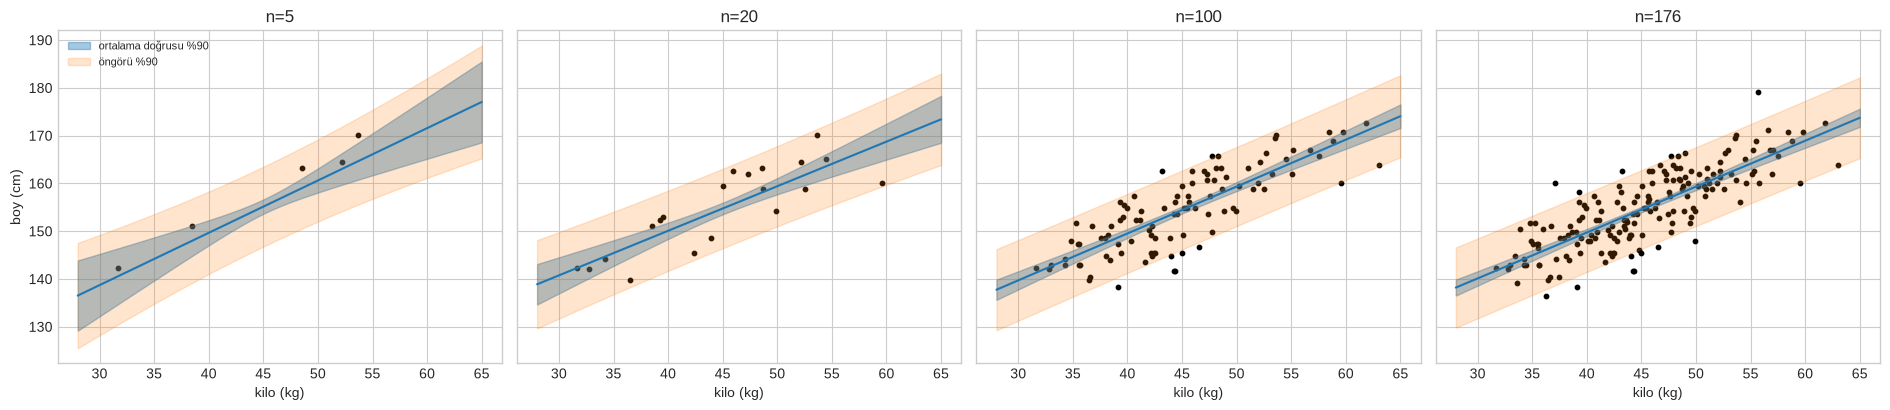

  n  eğim_ort  eğim_sd  x_ort_etrafi_ort_band
  5    1.0954   0.2552                 8.7031
 20    0.9332   0.1446                 5.3146
100    0.9818   0.0713                 2.7736
176    0.9605   0.0557                 2.1691

Kanıt-maks. model (n=176 eğitim, 176 test): %90 öngörü aralığı kapsama oranı = 0.864; test RMSE = 5.290 cm; gürültü sd tahmini = 4.894 cm
YORUM: n=5'te eğim posterior'u geniş (sd büyük) ve prior'a çekilmiş; n büyüdükçe eğim sd'si ~ 1/sqrt(n) küçülüyor ve ortalama-doğrusu bandı daralıyor — ama ÖNGÖRÜ bandı (turuncu) gürültü sd'sinde (~5 cm) takılıyor: parametre belirsizliği sıfıra gider, veri gürültüsü gitmez.
       Test kapsaması nominal %90'a yakın (176 örnekte tek bir oranın standart hatası ~0,02; test RMSE'si eğitim gürültü sd'sinden biraz büyük, yani test örneğinde bir miktar daha fazla saçılma var): model (doğrusal+Gauss gürültü) yetişkinler için iyi özellenmiş (Adım 5'te kötü özelleme durumunda kapsamanın nasıl çöktüğünü göreceğiz).


In [5]:
# Veri boyutu etkisi + öngörü bandı + kapsama (alt-örneklem ve ayrı test seti)
rng = np.random.default_rng(1); perm = rng.permutation(len(adult)); tr_i, te_i = perm[:176], perm[176:]
Xtr, ytr = xa[tr_i], ya[tr_i]; Xte, yte = xa[te_i], ya[te_i]
mx, my = Xtr.mean(), ytr.mean()
feat = lambda x: np.c_[np.ones(len(x)), x - mx]
grid_x = np.linspace(28, 65, 100)
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2), sharey=True)
rows = []
for a_, n_ in zip(ax, (5, 20, 100, 176)):
    idx = np.arange(n_) if n_ < 176 else np.arange(176)
    m_ = BayesLinReg(1.0, 1 / 5.0 ** 2).posterior(feat(Xtr[idx]), ytr[idx] - my)           # kaba prior: alpha=1, gürültü sd=5 cm varsayımı
    mu_, sd_p = m_.predict(feat(grid_x), noise=False); _, sd_n = m_.predict(feat(grid_x), noise=True)
    a_.scatter(Xtr[idx], ytr[idx], s=10, c='k'); a_.plot(grid_x, mu_ + my, 'C0')
    a_.fill_between(grid_x, mu_ + my - 1.645 * sd_p, mu_ + my + 1.645 * sd_p, color='C0', alpha=.4, label='ortalama doğrusu %90')
    a_.fill_between(grid_x, mu_ + my - 1.645 * sd_n, mu_ + my + 1.645 * sd_n, color='C1', alpha=.2, label='öngörü %90')
    a_.set(title=f'n={n_}', xlabel='kilo (kg)'); rows.append(dict(n=n_, eğim_ort=m_.m[1], eğim_sd=np.sqrt(m_.S[1, 1]), x_ort_etrafi_ort_band=2 * 1.645 * sd_p.mean()))
ax[0].set_ylabel('boy (cm)'); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))

# sabit-kanıt modeliyle test kapsaması
mfull = BayesLinReg().fit_evidence(feat(Xtr), ytr - my)
mu_t, sd_t = mfull.predict(feat(Xte)); mu_t = mu_t + my
cover = np.mean(np.abs(yte - mu_t) < 1.645 * sd_t)
print(f"\nKanıt-maks. model (n=176 eğitim, {len(Xte)} test): %90 öngörü aralığı kapsama oranı = {cover:.3f}; test RMSE = {np.sqrt(np.mean((yte-mu_t)**2)):.3f} cm; gürültü sd tahmini = {1/np.sqrt(mfull.beta):.3f} cm")
print("YORUM: n=5'te eğim posterior'u geniş (sd büyük) ve prior'a çekilmiş; n büyüdükçe eğim sd'si ~ 1/sqrt(n) küçülüyor ve ortalama-doğrusu bandı daralıyor — ama ÖNGÖRÜ bandı (turuncu) gürültü sd'sinde (~5 cm) takılıyor: parametre belirsizliği sıfıra gider, veri gürültüsü gitmez.")
print("       Test kapsaması nominal %90'a yakın (176 örnekte tek bir oranın standart hatası ~0,02; test RMSE'si eğitim gürültü sd'sinden biraz büyük, yani test örneğinde bir miktar daha fazla saçılma var): model (doğrusal+Gauss gürültü) yetişkinler için iyi özellenmiş (Adım 5'te kötü özelleme durumunda kapsamanın nasıl çöktüğünü göreceğiz).")

 derece  log_kanıt  sklearn_log_kanıt  alpha  gamma  cv_rmse_cm_bayes  cv_rmse_cm_ols
      1   -192.610           -192.610  0.564  1.999             9.439           9.439
      2     66.858             66.858  0.825  2.999             5.792           5.792
      3    158.261            158.261  0.951  3.998             4.865           4.865
      4    156.231            156.231  1.190  4.997             4.852           4.852
      5    155.893            155.893  1.447  5.994             4.828           4.828
      6    152.759            152.759  1.689  6.990             4.833           4.834
      7    149.749            149.749  1.930  7.986             4.845           4.846

Kanıtın seçtiği derece: 3 | 5-katlı CV'nin seçtiği derece: 5


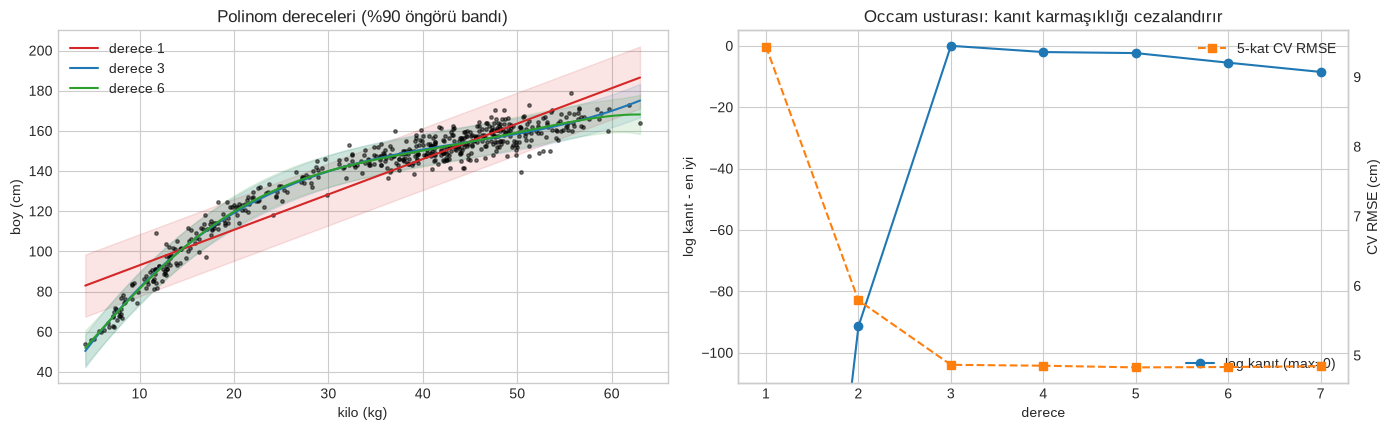

YORUM: Derece 1 açıkça yetersiz (CV RMSE ~9,4 cm), derece 3'te RMSE ~4.86 cm'e iniyor. Derece 3'ten sonra CV RMSE fark etmeyecek kadar küçük oynarken (4.828 - 4.865) log kanıt her derecede DÜŞÜYOR: kanıt, veriye ek katkı vermeyen parametreleri cezalandırıyor.
       Bu veri setinde kanıt, CV'nin 'fark yok' dediği yerde net bir tercih yapıyor (derece 3); çapraz doğrulama olmadan, tek bir fit'ten seçim. Not: ortak bir alpha kullandığımız (tüm katsayılar için aynı prior) basit bir prior; ARD (her katsayı için ayrı alpha) bunu rafine eder (bkz. E2).


In [6]:
# Tüm Howell1 (çocuklar dahil): boy~kilo eğri. Legendre polinom tabanı + KANIT ile derece seçimi
xs_all = (howell.weight.values - howell.weight.min()) / (howell.weight.max() - howell.weight.min()) * 2 - 1
y_all = howell.height.values; ym_, ysd_ = y_all.mean(), y_all.std(); yz = (y_all - ym_) / ysd_
rows = []; kf = KFold(5, shuffle=True, random_state=0)
for d in range(1, 8):
    Phi = Leg.legvander(xs_all, d); bl = BayesLinReg(1.0, 1.0).fit_evidence(Phi, yz)
    cv_b, cv_o = [], []
    for tr, te in kf.split(Phi):
        bl2 = BayesLinReg(1.0, 1.0).fit_evidence(Phi[tr], yz[tr]); cv_b.append(np.mean((yz[te] - Phi[te] @ bl2.m) ** 2))
        w_ = np.linalg.lstsq(Phi[tr], yz[tr], rcond=None)[0]; cv_o.append(np.mean((yz[te] - Phi[te] @ w_) ** 2))
    sk = BayesianRidge(fit_intercept=False, tol=1e-12, max_iter=5000, compute_score=True, alpha_1=0, alpha_2=0, lambda_1=0, lambda_2=0).fit(Phi, yz)
    rows.append(dict(derece=d, log_kanıt=bl.log_evidence(Phi, yz), sklearn_log_kanıt=sk.scores_[-1], alpha=bl.alpha, gamma=bl.gamma, cv_rmse_cm_bayes=np.sqrt(np.mean(cv_b)) * ysd_, cv_rmse_cm_ols=np.sqrt(np.mean(cv_o)) * ysd_))
ev = pd.DataFrame(rows); print(ev.round(3).to_string(index=False))
best_ev = int(ev.loc[ev.log_kanıt.idxmax(), 'derece']); best_cv = int(ev.loc[ev.cv_rmse_cm_bayes.idxmin(), 'derece'])
print(f"\nKanıtın seçtiği derece: {best_ev} | 5-katlı CV'nin seçtiği derece: {best_cv}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
gx = np.linspace(-1, 1, 200)
for d_, c_ in ((1, 'C3'), (3, 'C0'), (6, 'C2')):
    Phi = Leg.legvander(xs_all, d_); bl = BayesLinReg(1.0, 1.0).fit_evidence(Phi, yz); mu_, sd_ = bl.predict(Leg.legvander(gx, d_))
    wx = (gx + 1) / 2 * (howell.weight.max() - howell.weight.min()) + howell.weight.min()
    ax[0].plot(wx, mu_ * ysd_ + ym_, c_, label=f'derece {d_}'); ax[0].fill_between(wx, (mu_ - 1.645 * sd_) * ysd_ + ym_, (mu_ + 1.645 * sd_) * ysd_ + ym_, color=c_, alpha=.12)
ax[0].scatter(howell.weight, howell.height, s=6, c='k', alpha=.5); ax[0].legend(); ax[0].set(xlabel='kilo (kg)', ylabel='boy (cm)', title='Polinom dereceleri (%90 öngörü bandı)')
ax[1].plot(ev.derece, ev.log_kanıt - ev.log_kanıt.max(), 'o-', label='log kanıt (max=0)'); ax[1].set_ylim(-110, 5); ax[1].set(xlabel='derece', ylabel='log kanıt - en iyi', title='Occam usturası: kanıt karmaşıklığı cezalandırır')
ax2 = ax[1].twinx(); ax2.plot(ev.derece, ev.cv_rmse_cm_bayes, 's--', c='C1', label='5-kat CV RMSE'); ax2.set_ylabel('CV RMSE (cm)'); ax2.grid(False)
ax[1].legend(loc='lower right'); ax2.legend(loc='upper right'); plt.tight_layout(); plt.show()
print(f"YORUM: Derece 1 açıkça yetersiz (CV RMSE ~9,4 cm), derece 3'te RMSE ~{ev.loc[ev.derece==3,'cv_rmse_cm_bayes'].iloc[0]:.2f} cm'e iniyor. Derece 3'ten sonra CV RMSE fark etmeyecek kadar küçük oynarken ({ev.cv_rmse_cm_bayes.min():.3f} - {ev.loc[ev.derece==3,'cv_rmse_cm_bayes'].iloc[0]:.3f}) log kanıt her derecede DÜŞÜYOR: kanıt, veriye ek katkı vermeyen parametreleri cezalandırıyor.")
print("       Bu veri setinde kanıt, CV'nin 'fark yok' dediği yerde net bir tercih yapıyor (derece 3); çapraz doğrulama olmadan, tek bir fit'ten seçim. Not: ortak bir alpha kullandığımız (tüm katsayılar için aynı prior) basit bir prior; ARD (her katsayı için ayrı alpha) bunu rafine eder (bkz. E2).")

## Adım 3 · Bayesçi Lojistik Regresyon (Wells)

**Veri:** Bangladeş'te kuyu sularında arsenik kirliliği (Gelman & Hill). Hane arsenikli kuyuyu kullanıyor; "komşunun güvenli kuyusuna geçti mi?" (`switch`, %57,5 evet). Öznitelikler: `arsenic` (kuyu arsenik düzeyi), `distance` (en yakın güvenli kuyuya metre), `education` (hane reisi eğitim yılı), `association` (toplulukta üye mi). Ölçekler: arsenik merkezli, mesafe 100 m, eğitim 4 yıl birimiyle merkezli.

**Prior:** kesişim $\mathcal{N}(0,5^2)$ (zayıf), eğimler $\mathcal{N}(0,1)$ — standartlaştırılmış özniteliklerde makul "zayıf bilgilendirici" prior. Önce teorideki **elle Newton adımını** doğruluyoruz.

In [7]:
def logistic_map(X, y, alpha_vec, iters=100, tol=1e-12):
    """Newton-IRLS ile MAP. alpha_vec: katsayı başına prior kesinliği. (w_map, Sigma=H^-1, iter) döner."""
    w = np.zeros(X.shape[1]); A = np.diag(alpha_vec)
    for k in range(iters):
        p = expit(X @ w); g = X.T @ (y - p) - A @ w
        H = X.T @ (X * (p * (1 - p))[:, None]) + A
        step = np.linalg.solve(H, g); w = w + step
        if np.abs(step).max() < tol: break
    return w, np.linalg.inv(H), k + 1

def log_post(w, X, y, alpha_vec):
    z = X @ w; return y @ z - np.logaddexp(0, z).sum() - 0.5 * np.sum(alpha_vec * w ** 2)

# teorideki elle örnek: x=(-1,1,2), y=(0,1,1), alpha=1, kesişim yok
x3 = np.array([[-1.], [1.], [2.]]); y3 = np.array([0., 1., 1.]); p0 = expit(0 * x3[:, 0])
g0 = ((y3 - p0) * x3[:, 0]).sum(); H0 = (p0 * (1 - p0) * x3[:, 0] ** 2).sum() + 1.0
w_map3, S3, it3 = logistic_map(x3, y3, np.array([1.0]))
print(f"Elle: g={g0:.2f}, H={H0:.2f}, ilk Newton adımı w1={g0/H0:.2f} | yakınsayan MAP w={w_map3[0]:.4f} (iter={it3}), Laplace sd={np.sqrt(S3[0,0]):.4f}")

wells = pd.read_csv('data/wells.csv')
y_w = (wells.switch == 'yes').astype(float).values
Xw = np.c_[np.ones(len(wells)), wells.arsenic - wells.arsenic.mean(), (wells.distance - wells.distance.mean()) / 100,
           (wells.education - wells.education.mean()) / 4, (wells.association == 'yes').astype(float)]
names = ['kesişim', 'arsenik', 'mesafe(100m)', 'eğitim(4y)', 'topluluk']
alpha_vec = np.array([1 / 25, 1, 1, 1, 1.0])           # prior sd: 5, 1, 1, 1, 1
print(f"\nWells: {len(wells):,} hane | switch=evet oranı {y_w.mean():.3f} | arsenik ort. {wells.arsenic.mean():.2f} | mesafe ort. {wells.distance.mean():.1f} m")
print("Arsenik düzeyine göre geçiş oranı:"); print(wells.groupby(pd.cut(wells.arsenic, [0, .75, 1, 1.5, 2.5, 4, 10]), observed=True).switch.apply(lambda s: (s == 'yes').mean()).round(3).to_string())

Elle: g=2.00, H=2.50, ilk Newton adımı w1=0.80 | yakınsayan MAP w=0.8800 (iter=5), Laplace sd=0.7225

Wells: 3,020 hane | switch=evet oranı 0.575 | arsenik ort. 1.66 | mesafe ort. 48.3 m
Arsenik düzeyine göre geçiş oranı:
arsenic
(0.0, 0.75]    0.416
(0.75, 1.0]    0.539
(1.0, 1.5]     0.570
(1.5, 2.5]     0.632
(2.5, 4.0]     0.693
(4.0, 10.0]    0.796


In [8]:
w_map, Sig_map, k_it = logistic_map(Xw, y_w, alpha_vec)
mle_sm = sm.Logit(y_w, Xw).fit(disp=0)
sk = LogisticRegression(C=1.0, fit_intercept=True, tol=1e-12, max_iter=5000).fit(Xw[:, 1:], y_w)      # kesişim cezasız, eğimler N(0,1) prior = C=1
w_map_noint, _, _ = logistic_map(Xw, y_w, np.array([0, 1, 1, 1, 1.0]))
print(f"Newton {k_it} iterasyonda yakınsadı.\n")
tab = pd.DataFrame({'MLE (statsmodels)': mle_sm.params, 'MAP (bizim)': w_map, 'Laplace sd': np.sqrt(np.diag(Sig_map)), 'MLE sd': mle_sm.bse}, index=names)
print(tab.round(4).to_string())
print(f"\nDoğrulama: sklearn LogisticRegression(C=1) vs bizim MAP (kesişim cezasız, eğim prior N(0,1)): maks. fark = {np.abs(np.r_[sk.intercept_, sk.coef_[0]] - w_map_noint).max():.2e}")
print(f"Doğrulama: Hessian'dan Laplace sd'ler statsmodels MLE sd'leriyle farkı (prior etkisi küçük, n=3020): maks. {np.abs(np.sqrt(np.diag(Sig_map)) - mle_sm.bse).max():.4f}")
print("YORUM: n=3020'de MAP ile MLE neredeyse aynı (prior etkisi ihmal edilebilir) ve sklearn ile bizim MAP eşleşiyor. Mesafe arttıkça (-0.9/100 m) geçiş olasılığı düşüyor, arsenik arttıkça (+0.47) yükseliyor.")
print("       Katsayıları odds oranına çevir: arsenik +1 birim -> odds x%.2f; mesafe +100 m -> odds x%.2f." % (np.exp(w_map[1]), np.exp(w_map[2])))

Newton 6 iterasyonda yakınsadı.

              MLE (statsmodels)  MAP (bizim)  Laplace sd  MLE sd
kesişim                  0.3890       0.3883      0.0506  0.0507
arsenik                  0.4670       0.4652      0.0415  0.0416
mesafe(100m)            -0.8961      -0.8859      0.1039  0.1046
eğitim(4y)               0.1698       0.1695      0.0383  0.0384
topluluk                -0.1243      -0.1235      0.0767  0.0770

Doğrulama: sklearn LogisticRegression(C=1) vs bizim MAP (kesişim cezasız, eğim prior N(0,1)): maks. fark = 9.52e-09
Doğrulama: Hessian'dan Laplace sd'ler statsmodels MLE sd'leriyle farkı (prior etkisi küçük, n=3020): maks. 0.0007
YORUM: n=3020'de MAP ile MLE neredeyse aynı (prior etkisi ihmal edilebilir) ve sklearn ile bizim MAP eşleşiyor. Mesafe arttıkça (-0.9/100 m) geçiş olasılığı düşüyor, arsenik arttıkça (+0.47) yükseliyor.
       Katsayıları odds oranına çevir: arsenik +1 birim -> odds x1.59; mesafe +100 m -> odds x0.41.


4 zincir x 15000 adım: 6.1 s


              MH ort.   MH sd  Laplace ort.  Laplace sd   R-hat        ESS
kesişim        0.3869  0.0514        0.3883      0.0506  1.0012  3010.7268
arsenik        0.4669  0.0419        0.4652      0.0415  1.0013  2571.4615
mesafe(100m)  -0.8876  0.1022       -0.8859      0.1039  1.0029  3027.5702
eğitim(4y)     0.1693  0.0385        0.1695      0.0383  1.0008  2814.0230
topluluk      -0.1220  0.0774       -0.1235      0.0767  1.0006  2935.8317
kabul oranları: [0.285 0.287 0.289 0.289]  (toplam örnek 48,000)


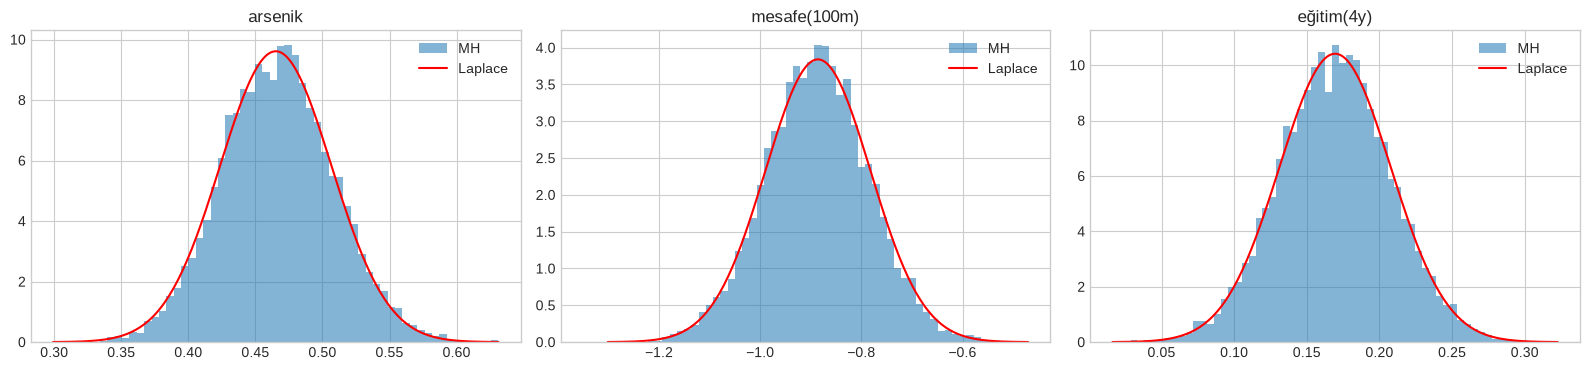

YORUM: n=3020'de posterior neredeyse tam Gauss (Bernstein-von Mises: veri çoğaldıkça posterior normale yaklaşır): MH marjinalleri Laplace ile örtüşüyor; R-hat ~1,00, kabul oranı %20-35 aralığında.


In [9]:
# MCMC: 4 zincir, dağınık başlangıç, Laplace kovaryansından türetilen öneri (boyuta göre 2.38/sqrt(d))
def run_chains(X, y, alpha_vec, w_map, Sigma, n=15000, burn=3000, seed=0, scale=None):
    d = X.shape[1]; L = np.linalg.cholesky(Sigma); scale = 2.38 / np.sqrt(d) if scale is None else scale
    out, accs = [], []
    for c in range(4):
        rng_ = np.random.default_rng(seed + c); w0 = w_map + 3 * np.sqrt(np.diag(Sigma)) * rng_.standard_normal(d)   # dağınık başlangıç
        ch, acc = metropolis(lambda w: log_post(w, X, y, alpha_vec), w0, n, scale, rng_, chol=L); out.append(ch[burn:]); accs.append(acc)
    return np.array(out), np.array(accs)          # (zincir, n, d)

t0 = time.time(); ch_full, acc_full = run_chains(Xw, y_w, alpha_vec, w_map, Sig_map); print(f"4 zincir x 15000 adım: {time.time()-t0:.1f} s")
diag = pd.DataFrame({'MH ort.': ch_full.mean((0, 1)), 'MH sd': ch_full.reshape(-1, 5).std(0), 'Laplace ort.': w_map, 'Laplace sd': np.sqrt(np.diag(Sig_map)),
                     'R-hat': [rhat(ch_full[:, :, j]) for j in range(5)], 'ESS': [ess(ch_full[:, :, j]) for j in range(5)]}, index=names)
print(diag.round(4).to_string()); print(f"kabul oranları: {acc_full.round(3)}  (toplam örnek {ch_full.shape[0]*ch_full.shape[1]:,})")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a_, j in zip(ax, (1, 2, 3)):
    a_.hist(ch_full[:, :, j].ravel(), bins=60, density=True, alpha=.55, label='MH'); xs_ = np.linspace(w_map[j] - 4 * np.sqrt(Sig_map[j, j]), w_map[j] + 4 * np.sqrt(Sig_map[j, j]), 200)
    a_.plot(xs_, stats.norm(w_map[j], np.sqrt(Sig_map[j, j])).pdf(xs_), 'r', label='Laplace'); a_.set(title=names[j]); a_.legend()
plt.tight_layout(); plt.show()
print("YORUM: n=3020'de posterior neredeyse tam Gauss (Bernstein-von Mises: veri çoğaldıkça posterior normale yaklaşır): MH marjinalleri Laplace ile örtüşüyor; R-hat ~1,00, kabul oranı %20-35 aralığında.")

### Küçük veri: Laplace ne zaman yetersiz kalır?

Aynı modeli **sadece 25 haneyle** kuralım. Posterior artık Gauss'a benzemiyor (çarpık, kuyruklu); MLE de zayıf güvenilir. Laplace (MAP + $\mathbf{H}^{-1}$) ve MCMC'yi karşılaştırıyoruz.

n=25 (geçiş=evet: 13/25); kabul oranları [0.31 0.31 0.31 0.31]
                MLE    MAP  MH ortalaması  Laplace sd  MH sd  R-hat       ESS
kesişim       0.530  0.307          0.430       0.571  0.614  1.001  5627.941
arsenik       1.156  0.893          1.090       0.460  0.495  1.000  5087.507
mesafe(100m)  0.942  0.380          0.399       0.777  0.804  1.001  6356.487
eğitim(4y)   -0.029  0.014         -0.004       0.403  0.432  1.001  5923.415
topluluk     -0.324 -0.158         -0.188       0.676  0.695  1.001  6199.020

Posterior çarpıklığı (MH): {'kesişim': 0.13, 'arsenik': 0.48, 'mesafe(100m)': 0.03, 'eğitim(4y)': 0.04, 'topluluk': 0.01}
Arsenik katsayısı: MAP=0.89 ama MH ortalaması=1.09; %90 güvenilir aralık (MH) = [0.35, 1.97] | Laplace = [0.14, 1.65]


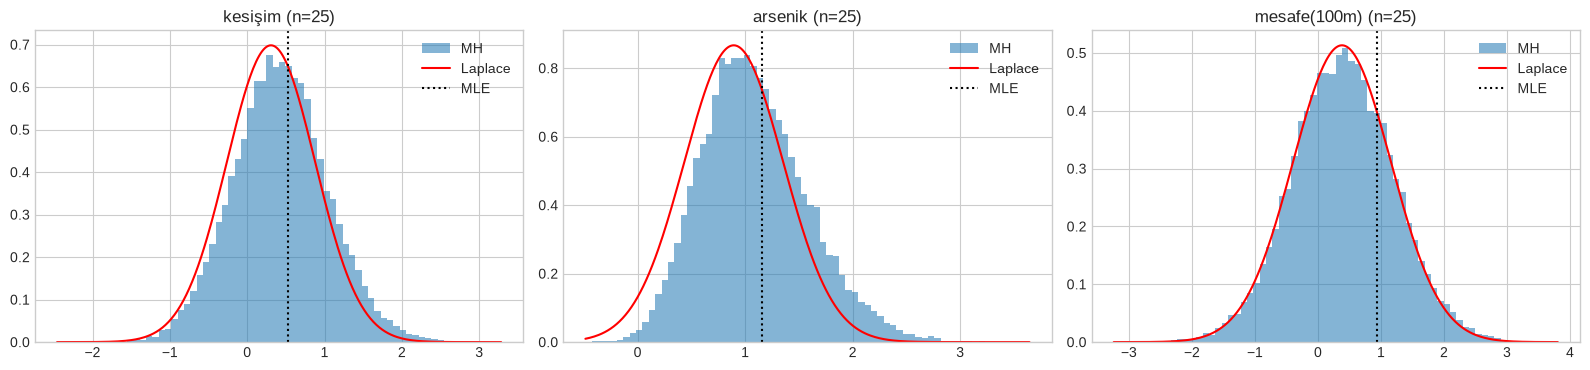

YORUM: n=25'te MLE ile MAP arasında büyük fark var (mesafe katsayısı: MLE +0.94, MAP +0.38; n=3020'deki değer -0.89): 25 haneyle MLE mesafe etkisinin İŞARETİNİ bile yanlış buldu, prior katsayıyı sıfıra doğru çekti.
       MH sd'leri Laplace sd'lerinden %3-%8 büyük; arsenik katsayısı sağa çarpık (çarpıklık 0.48) ve %90 aralığı Laplace'ınkinden sağa kaymış: Laplace simetrik Gauss varsaydığı için kuyruğu kaçırıyor. Diğer katsayılar neredeyse simetrik.


In [10]:
rng = np.random.default_rng(1); idx25 = rng.choice(len(y_w), 25, replace=False)
X25, y25 = Xw[idx25], y_w[idx25]
mle25 = sm.Logit(y25, X25).fit(disp=0, maxiter=200)
w25, S25, _ = logistic_map(X25, y25, alpha_vec)
ch25, acc25 = run_chains(X25, y25, alpha_vec, w25, S25, n=30000, burn=5000, seed=10)
post25 = ch25.reshape(-1, 5)
tab25 = pd.DataFrame({'MLE': mle25.params, 'MAP': w25, 'MH ortalaması': post25.mean(0), 'Laplace sd': np.sqrt(np.diag(S25)), 'MH sd': post25.std(0),
                      'R-hat': [rhat(ch25[:, :, j]) for j in range(5)], 'ESS': [ess(ch25[:, :, j]) for j in range(5)]}, index=names)
print(f"n=25 (geçiş=evet: {int(y25.sum())}/25); kabul oranları {acc25.round(2)}"); print(tab25.round(3).to_string())
print("\nPosterior çarpıklığı (MH):", {k: round(float(v), 2) for k, v in zip(names, stats.skew(post25))})
print(f"Arsenik katsayısı: MAP={w25[1]:.2f} ama MH ortalaması={post25[:,1].mean():.2f}; %90 güvenilir aralık (MH) = [{np.quantile(post25[:,1],.05):.2f}, {np.quantile(post25[:,1],.95):.2f}] | Laplace = [{w25[1]-1.645*np.sqrt(S25[1,1]):.2f}, {w25[1]+1.645*np.sqrt(S25[1,1]):.2f}]")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a_, j in zip(ax, (0, 1, 2)):
    a_.hist(post25[:, j], bins=70, density=True, alpha=.55, label='MH'); xs_ = np.linspace(post25[:, j].min(), post25[:, j].max(), 300)
    a_.plot(xs_, stats.norm(w25[j], np.sqrt(S25[j, j])).pdf(xs_), 'r', label='Laplace'); a_.axvline(mle25.params[j], c='k', ls=':', label='MLE'); a_.set(title=f'{names[j]} (n=25)'); a_.legend()
plt.tight_layout(); plt.show()
print(f"YORUM: n=25'te MLE ile MAP arasında büyük fark var (mesafe katsayısı: MLE {mle25.params[2]:+.2f}, MAP {w25[2]:+.2f}; n=3020'deki değer {w_map[2]:+.2f}): 25 haneyle MLE mesafe etkisinin İŞARETİNİ bile yanlış buldu, prior katsayıyı sıfıra doğru çekti.")
print(f"       MH sd'leri Laplace sd'lerinden %{(post25.std(0)/np.sqrt(np.diag(S25))-1).min()*100:.0f}-%{(post25.std(0)/np.sqrt(np.diag(S25))-1).max()*100:.0f} büyük; arsenik katsayısı sağa çarpık (çarpıklık {stats.skew(post25[:,1]):.2f}) ve %90 aralığı Laplace'ınkinden sağa kaymış: Laplace simetrik Gauss varsaydığı için kuyruğu kaçırıyor. Diğer katsayılar neredeyse simetrik.")

In [11]:
# Öngörü: belirli bir hane için geçiş olasılığı. Yöntemler: MLE plug-in, MAP plug-in, Laplace-probit, MH (tam Bayes)
def household(ars, dist, edu, assoc, ref=wells):
    return np.array([1, ars - ref.arsenic.mean(), (dist - ref.distance.mean()) / 100, (edu - ref.education.mean()) / 4, assoc])
hh = household(3.0, 200.0, 5, 0)                                     # yüksek arsenik, güvenli kuyu 200 m uzakta
def predict_summary(w_mle, w_map_, S_, samples, x):
    mu, v = w_map_ @ x, x @ S_ @ x; probit = expit(mu / np.sqrt(1 + np.pi * v / 8))
    p_s = expit(samples @ x); return dict(MLE_plugin=expit(w_mle @ x), MAP_plugin=expit(mu), Laplace_probit=probit, MH_tam_Bayes=p_s.mean(), MH_p_5=np.quantile(p_s, .05), MH_p_95=np.quantile(p_s, .95))
res = pd.DataFrame({'n=25': predict_summary(mle25.params, w25, S25, post25, hh), 'n=3020': predict_summary(mle_sm.params, w_map, Sig_map, ch_full.reshape(-1, 5), hh)})
print("Hane: arsenik=3.0, mesafe=200 m, eğitim=5 yıl, topluluk=hayır -> geçiş olasılığı"); print(res.round(3).to_string())
print(f"YORUM: Aynı hane için n=25 modeli {res.loc['MLE_plugin','n=25']:.2f} (MLE plug-in), {res.loc['MH_tam_Bayes','n=25']:.2f} (tam Bayes) diyor; n=3020 modeli ise {res.loc['MAP_plugin','n=3020']:.2f}. Küçük örnekte MLE aşırı özgüvenli ve yanlış işaretli mesafe katsayısı yüzünden çok uzakta; prior ve belirsizlik ortalaması tahmini {res.loc['MLE_plugin','n=25']-res.loc['MH_tam_Bayes','n=25']:.2f} puan geri çekiyor ama yine de uzakta.")
print(f"       n=25 için MH %5-%95 aralığı [{res.loc['MH_p_5','n=25']:.2f}, {res.loc['MH_p_95','n=25']:.2f}] n=3020 referansını ({res.loc['MAP_plugin','n=3020']:.2f}) KAPSAMIYOR: bu tek bir 25'lik örnek (kanıt değil, örnek), ama posterior'un da yanıltabileceğini gösteriyor - prior N(0,1) ve verinin 'yanlış yöne' esen bir örneği; Bayes sihir değil, belirsizliği dürüstçe ifade eden bir çerçeve.")
print("       Aynı hane için olasılığın kendisinin belirsizliği (MH %5-%95 aralığı) n=25'te çok geniş, n=3020'de dar: tek bir plug-in olasılığı bu farkı göstermez.")

Hane: arsenik=3.0, mesafe=200 m, eğitim=5 yıl, topluluk=hayır -> geçiş olasılığı
                 n=25  n=3020
MLE_plugin      0.971   0.417
MAP_plugin      0.889   0.420
Laplace_probit  0.822   0.420
MH_tam_Bayes    0.859   0.420
MH_p_5          0.507   0.357
MH_p_95         0.994   0.484
YORUM: Aynı hane için n=25 modeli 0.97 (MLE plug-in), 0.86 (tam Bayes) diyor; n=3020 modeli ise 0.42. Küçük örnekte MLE aşırı özgüvenli ve yanlış işaretli mesafe katsayısı yüzünden çok uzakta; prior ve belirsizlik ortalaması tahmini 0.11 puan geri çekiyor ama yine de uzakta.
       n=25 için MH %5-%95 aralığı [0.51, 0.99] n=3020 referansını (0.42) KAPSAMIYOR: bu tek bir 25'lik örnek (kanıt değil, örnek), ama posterior'un da yanıltabileceğini gösteriyor - prior N(0,1) ve verinin 'yanlış yöne' esen bir örneği; Bayes sihir değil, belirsizliği dürüstçe ifade eden bir çerçeve.
       Aynı hane için olasılığın kendisinin belirsizliği (MH %5-%95 aralığı) n=25'te çok geniş, n=3020'de dar: tek bir plug-in ola

                            logloss           brier        
                               mean     std    mean     std
n    yöntem                                                
25   Bayes (Laplace-probit)  0.6953  0.0431  0.2496  0.0185
     MAP                     0.7090  0.0631  0.2532  0.0226
     MLE                     0.8012  0.1692  0.2713  0.0382
60   Bayes (Laplace-probit)  0.6819  0.0279  0.2430  0.0114
     MAP                     0.6876  0.0328  0.2444  0.0125
     MLE                     0.7082  0.0530  0.2499  0.0169
200  Bayes (Laplace-probit)  0.6599  0.0095  0.2334  0.0039
     MAP                     0.6612  0.0103  0.2336  0.0041
     MLE                     0.6640  0.0129  0.2344  0.0048
1000 Bayes (Laplace-probit)  0.6492  0.0037  0.2288  0.0015
     MAP                     0.6493  0.0038  0.2288  0.0016
     MLE                     0.6493  0.0039  0.2288  0.0016


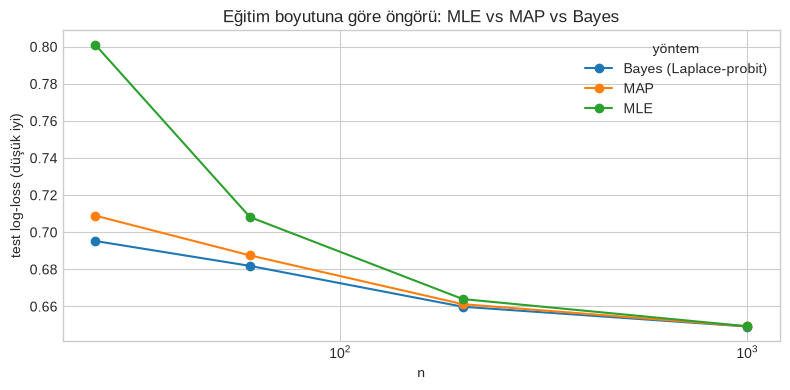

YORUM: Küçük n'de MLE en kötü (log-loss yüksek, aşırı özgüvenli olasılıklar), prior'lu MAP onu düzeltiyor, Laplace-probit (belirsizliği olasılığa yansıtan) en iyi ya da eşit. n büyüdükçe üçü birleşiyor — Bayesçi yaklaşımın getirisi tam da veri kıt olduğunda.
       Not: 'MLE' burada 1e-8'lik minik ridge ile 60 Newton adımı (ayrışabilir küçük örneklerde sayısal olarak sonlu kalsın diye); gerçek MLE ayrışmada sonsuza gider.


In [12]:
# Tekrarlı hold-out: eğitim boyutu n'e göre öngörü performansı (log-loss, Brier): MLE vs MAP vs Bayes (Laplace-probit)
def pred_laplace_probit(w_, S_, X):
    mu = X @ w_; v = np.einsum('ij,jk,ik->i', X, S_, X); return expit(mu / np.sqrt(1 + np.pi * v / 8))
rows = []
for n_tr in (25, 60, 200, 1000):
    for rep in range(30):
        r_ = np.random.default_rng(1000 * n_tr + rep); perm = r_.permutation(len(y_w)); tr, te = perm[:n_tr], perm[n_tr:]
        Xt, yt = Xw[tr], y_w[tr]
        w_mle_, _, _ = logistic_map(Xt, yt, np.full(5, 1e-8), iters=60)           # "MLE" (ayrışabilir veride 60 adımda durur, ağırlıklar büyür)
        w_m, S_m, _ = logistic_map(Xt, yt, alpha_vec)
        for nm, p in (('MLE', expit(Xw[te] @ w_mle_)), ('MAP', expit(Xw[te] @ w_m)), ('Bayes (Laplace-probit)', pred_laplace_probit(w_m, S_m, Xw[te]))):
            p = np.clip(p, 1e-12, 1 - 1e-12); rows.append(dict(n=n_tr, yöntem=nm, logloss=-np.mean(y_w[te] * np.log(p) + (1 - y_w[te]) * np.log(1 - p)), brier=np.mean((p - y_w[te]) ** 2)))
perf = pd.DataFrame(rows).groupby(['n', 'yöntem'])[['logloss', 'brier']].agg(['mean', 'std']).round(4)
print(perf.to_string())
ll = pd.DataFrame(rows).pivot_table(index='n', columns='yöntem', values='logloss', aggfunc='mean')
fig, ax = plt.subplots(figsize=(8, 4)); ll.plot(marker='o', ax=ax); ax.set(ylabel='test log-loss (düşük iyi)', title='Eğitim boyutuna göre öngörü: MLE vs MAP vs Bayes'); ax.set_xscale('log'); plt.tight_layout(); plt.show()
print("YORUM: Küçük n'de MLE en kötü (log-loss yüksek, aşırı özgüvenli olasılıklar), prior'lu MAP onu düzeltiyor, Laplace-probit (belirsizliği olasılığa yansıtan) en iyi ya da eşit. n büyüdükçe üçü birleşiyor — Bayesçi yaklaşımın getirisi tam da veri kıt olduğunda.")
print("       Not: 'MLE' burada 1e-8'lik minik ridge ile 60 Newton adımı (ayrışabilir küçük örneklerde sayısal olarak sonlu kalsın diye); gerçek MLE ayrışmada sonsuza gider.")

## Adım 4 · Gaussian Process Regresyonu (mcycle)

**Veri:** Motosiklet çarpma simülasyonunda zamana ($ms$) karşı baş ivmesi ($g$): 133 ölçüm, **gürültü zamana göre değişiyor** (başlangıçta ~0, çarpmada büyük). Klasik "parametrik model yazamayız, esnek fonksiyon lazım" örneği ve GP'nin **varsayımlarını** (sabit gürültü) sınamak için ideal.

Önce `rbf_kernel`, Cholesky ile **log marjinal olabilirlik**, öngörü ve hiperparametre öğrenimini **sıfırdan** yazıyoruz; teori bölümündeki 2 noktalı elle örneği doğruluyoruz; sonra `sklearn.GaussianProcessRegressor` ile karşılaştırıyoruz. Hedef, ortalama 0 / sd 1 olacak şekilde standartlaştırılır.

In [13]:
def rbf_kernel(A, B, ell, sf2):
    d2 = (A[:, None] - B[None, :]) ** 2; return sf2 * np.exp(-0.5 * d2 / ell ** 2)

def gp_nlml(theta, x, y):
    """Negatif log marjinal olabilirlik; theta = log([ell, sf2, sn2])."""
    ell, sf2, sn2 = np.exp(theta); K = rbf_kernel(x, x, ell, sf2) + (sn2 + 1e-10) * np.eye(len(x))
    try: L = np.linalg.cholesky(K)
    except np.linalg.LinAlgError: return 1e10
    a = linalg.cho_solve((L, True), y)
    return 0.5 * y @ a + np.log(np.diag(L)).sum() + 0.5 * len(x) * np.log(2 * np.pi)

def gp_predict(theta, x, y, xs, noise=False):
    ell, sf2, sn2 = np.exp(theta); K = rbf_kernel(x, x, ell, sf2) + (sn2 + 1e-10) * np.eye(len(x)); L = np.linalg.cholesky(K)
    Ks = rbf_kernel(x, xs, ell, sf2); a = linalg.cho_solve((L, True), y); v = linalg.solve_triangular(L, Ks, lower=True)
    mean = Ks.T @ a; var = sf2 - np.sum(v ** 2, axis=0) + (sn2 if noise else 0.0); return mean, np.sqrt(np.maximum(var, 1e-12))

# teori bölümündeki 2 noktalı örnek: ell=1, sf2=1, sn2=0.01
th0 = np.log([1.0, 1.0, 0.01]); mu0, sd0 = gp_predict(th0, np.array([0., 1.]), np.array([0., 1.]), np.array([0.5, 5.0]))
print(f"Elle örnek: x*=0.5 -> ortalama={mu0[0]:.4f}, sd={sd0[0]:.4f} (varyans {sd0[0]**2:.4f}) | x*=5 (veriden uzak) -> ortalama={mu0[1]:.4f}, sd={sd0[1]:.4f} (prior'a dönüş)")

mc = pd.read_csv('data/mcycle.csv'); xm = mc.times.values; ym = mc.accel.values
y_mean, y_std = ym.mean(), ym.std(); yz_m = (ym - y_mean) / y_std
print(f"\nmcycle: {len(mc)} ölçüm, zaman {xm.min():.1f}-{xm.max():.1f} ms, aynı zamanda tekrarlı ölçüm sayısı: {int((np.diff(xm)==0).sum())} | ivme {ym.min():.0f} .. {ym.max():.0f} g")

Elle örnek: x*=0.5 -> ortalama=0.5459, sd=0.1909 (varyans 0.0365) | x*=5 (veriden uzak) -> ortalama=0.0005, sd=1.0000 (prior'a dönüş)

mcycle: 133 ölçüm, zaman 2.4-57.6 ms, aynı zamanda tekrarlı ölçüm sayısı: 39 | ivme -134 .. 75 g


In [14]:
# Hiperparametre öğrenimi: log marjinal olabilirliği maksimize et (L-BFGS-B, birkaç farklı başlangıç)
best = None
for s in range(6):
    th_init = np.log([np.exp(np.random.default_rng(s).uniform(np.log(1), np.log(30))), 1.0, np.random.default_rng(s + 50).uniform(0.05, 1)])
    r = optimize.minimize(gp_nlml, th_init, args=(xm, yz_m), method='L-BFGS-B', bounds=[(np.log(0.1), np.log(100)), (np.log(1e-3), np.log(100)), (np.log(1e-4), np.log(10))])
    if best is None or r.fun < best.fun: best = r
theta_hat = best.x; ell_h, sf2_h, sn2_h = np.exp(theta_hat)
print(f"Bizim optimum: ell={ell_h:.3f} ms, sf2={sf2_h:.3f}, sn2={sn2_h:.3f} | log marjinal olabilirlik={-best.fun:.3f}")

kern = C(1.0) * RBF(5.0) + WhiteKernel(0.5)
gp_sk = GaussianProcessRegressor(kern, n_restarts_optimizer=5, random_state=0).fit(xm[:, None], yz_m)
print(f"sklearn optimum: {gp_sk.kernel_} | log marjinal olabilirlik={gp_sk.log_marginal_likelihood_value_:.3f}")

# Aynı hiperparametrelerde birebir öngörü karşılaştırması (optimizasyon farkını dışarıda bırakmak için)
xs_g = np.linspace(0, 60, 300)
sk_fixed = GaussianProcessRegressor(C(sf2_h) * RBF(ell_h) + WhiteKernel(sn2_h), optimizer=None).fit(xm[:, None], yz_m)
m_sk, s_sk = sk_fixed.predict(xs_g[:, None], return_std=True); m_us, s_us = gp_predict(theta_hat, xm, yz_m, xs_g, noise=True)
print(f"\nAynı hiperparametreler: ortalama maks. farkı={np.abs(m_sk - m_us).max():.2e}, sd maks. farkı={np.abs(s_sk - s_us).max():.2e}  (sklearn'in return_std'si gürültü dahil gözlem sd'si)")
print(f"Log marjinal olabilirlik (aynı theta): bizim {-gp_nlml(theta_hat, xm, yz_m):.6f} | sklearn {sk_fixed.log_marginal_likelihood_value_:.6f}")

Bizim optimum: ell=5.216 ms, sf2=0.888, sn2=0.220 | log marjinal olabilirlik=-105.980


sklearn optimum: 0.942**2 * RBF(length_scale=5.22) + WhiteKernel(noise_level=0.22) | log marjinal olabilirlik=-105.980

Aynı hiperparametreler: ortalama maks. farkı=9.33e-15, sd maks. farkı=7.77e-16  (sklearn'in return_std'si gürültü dahil gözlem sd'si)
Log marjinal olabilirlik (aynı theta): bizim -105.980120 | sklearn -105.980120


LOO RMSE = 23.15 g | LOO %90 aralığı kapsaması = 0.895
                         n  kapsama  ort_abs_z
bölge                                         
çarpma öncesi (<14 ms)  21    1.000      0.149
çarpma (14-30)          69    0.899      0.853
sonrası (>30)           43    0.837      0.859


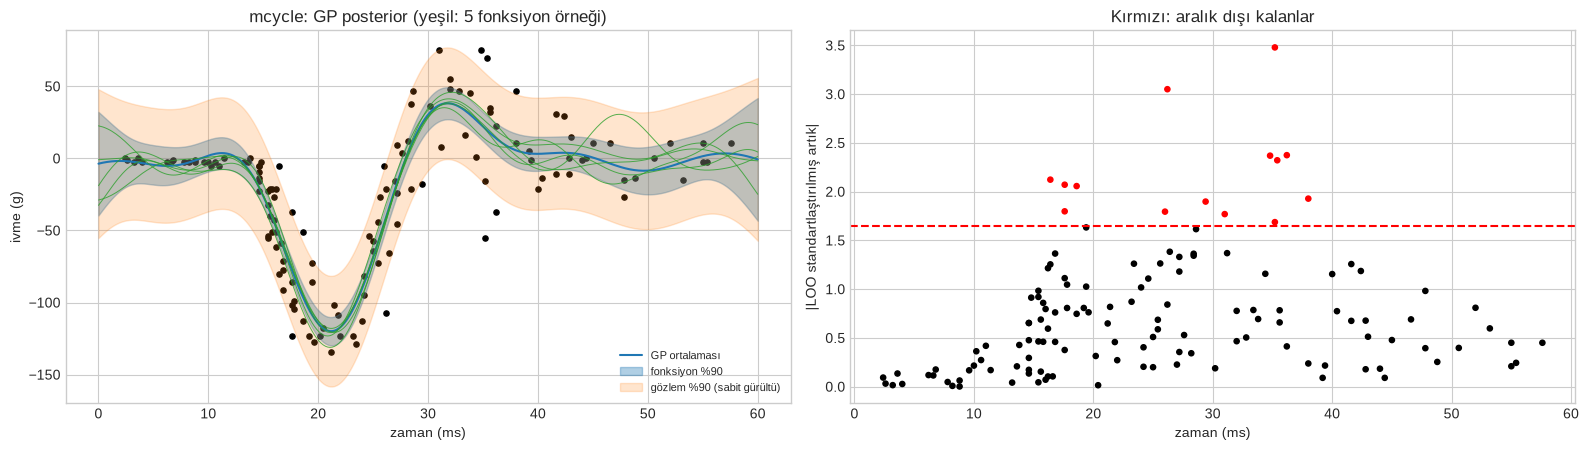

YORUM: Bizim GP, aynı hiperparametrelerde sklearn ile makine hassasiyetinde eşleşiyor; hiperparametre optimumu da (log marjinal olabilirlik) aynı. LOO tahminleri tek Cholesky/ters matrisle kapalı formda geliyor — 133 ayrı fit gerekmiyor.
       Genel LOO kapsaması nominal %90'a yakın (0.89); ama bölgelere bakınca kalibrasyon düzgün DEĞİL: çarpma öncesinde (gürültü ~0) ortalama |z| = 0.15 (N(0,1) için beklenen ~0,80) → aralıklar aşırı geniş (kapsama 100%); çarpma sonrasında kapsama 84% < %90 → aralıklar biraz dar.
       Sebep: GP TEK bir gürültü düzeyi (sn2) öğreniyor, oysa gerçek gürültü zamana göre değişiyor (heteroscedastic). Ortalama kapsama bu bölgesel hataları birbirine karşı dengeleyip gizliyor; çözümler: heteroscedastic GP, girdi-bağımlı gürültü modeli.


In [15]:
# Leave-one-out öngörüsü KAPALI FORMDA (GP'nin güzel özelliği): mu_-i = y_i - [Ky^-1 y]_i / [Ky^-1]_ii ; var_-i = 1/[Ky^-1]_ii
ell, sf2, sn2 = np.exp(theta_hat); Ky = rbf_kernel(xm, xm, ell, sf2) + sn2 * np.eye(len(xm)); Ki = np.linalg.inv(Ky)
loo_mu = yz_m - (Ki @ yz_m) / np.diag(Ki); loo_sd = np.sqrt(1 / np.diag(Ki))
loo_rmse = np.sqrt(np.mean((yz_m - loo_mu) ** 2)) * y_std; loo_cov = np.mean(np.abs(yz_m - loo_mu) < 1.645 * loo_sd)
print(f"LOO RMSE = {loo_rmse:.2f} g | LOO %90 aralığı kapsaması = {loo_cov:.3f}")
reg = pd.cut(xm, [0, 14, 30, 60], labels=['çarpma öncesi (<14 ms)', 'çarpma (14-30)', 'sonrası (>30)'])
z = (yz_m - loo_mu) / loo_sd
print(pd.DataFrame({'bölge': reg, 'kapsama': np.abs(z) < 1.645, '|z|': np.abs(z)}).groupby('bölge', observed=True).agg(n=('kapsama', 'size'), kapsama=('kapsama', 'mean'), ort_abs_z=('|z|', 'mean')).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
mu_f, sd_f = gp_predict(theta_hat, xm, yz_m, xs_g, noise=False); mu_n, sd_n = gp_predict(theta_hat, xm, yz_m, xs_g, noise=True)
ax[0].scatter(xm, ym, s=14, c='k'); ax[0].plot(xs_g, mu_f * y_std + y_mean, 'C0', label='GP ortalaması')
ax[0].fill_between(xs_g, (mu_f - 1.645 * sd_f) * y_std + y_mean, (mu_f + 1.645 * sd_f) * y_std + y_mean, color='C0', alpha=.35, label='fonksiyon %90')
ax[0].fill_between(xs_g, (mu_n - 1.645 * sd_n) * y_std + y_mean, (mu_n + 1.645 * sd_n) * y_std + y_mean, color='C1', alpha=.2, label='gözlem %90 (sabit gürültü)')
L_ = np.linalg.cholesky(rbf_kernel(xs_g, xs_g, ell, sf2) + 1e-8 * np.eye(len(xs_g)) - 0)                      # posterior örnekleri
Ks_ = rbf_kernel(xm, xs_g, ell, sf2); Lk = np.linalg.cholesky(Ky); V = linalg.solve_triangular(Lk, Ks_, lower=True)
post_cov = rbf_kernel(xs_g, xs_g, ell, sf2) - V.T @ V + 1e-8 * np.eye(len(xs_g)); smp = np.random.default_rng(0).multivariate_normal(mu_f, post_cov, size=5, method='cholesky')
for s_ in smp: ax[0].plot(xs_g, s_ * y_std + y_mean, lw=.7, alpha=.8, c='C2')
ax[0].set(xlabel='zaman (ms)', ylabel='ivme (g)', title='mcycle: GP posterior (yeşil: 5 fonksiyon örneği)'); ax[0].legend(fontsize=8, loc='lower right')
ax[1].scatter(xm, np.abs(z), s=14, c=np.where(np.abs(z) > 1.645, 'r', 'k')); ax[1].axhline(1.645, c='r', ls='--'); ax[1].set(xlabel='zaman (ms)', ylabel='|LOO standartlaştırılmış artık|', title='Kırmızı: aralık dışı kalanlar')
plt.tight_layout(); plt.show()
reg_tab = pd.DataFrame({'bölge': reg, 'kapsama': np.abs(z) < 1.645, 'abs_z': np.abs(z)}).groupby('bölge', observed=True).agg(kapsama=('kapsama', 'mean'), abs_z=('abs_z', 'mean'))
print("YORUM: Bizim GP, aynı hiperparametrelerde sklearn ile makine hassasiyetinde eşleşiyor; hiperparametre optimumu da (log marjinal olabilirlik) aynı. LOO tahminleri tek Cholesky/ters matrisle kapalı formda geliyor — 133 ayrı fit gerekmiyor.")
print(f"       Genel LOO kapsaması nominal %90'a yakın ({loo_cov:.2f}); ama bölgelere bakınca kalibrasyon düzgün DEĞİL: çarpma öncesinde (gürültü ~0) ortalama |z| = {reg_tab.abs_z.iloc[0]:.2f} (N(0,1) için beklenen ~0,80) → aralıklar aşırı geniş (kapsama {reg_tab.kapsama.iloc[0]:.0%}); çarpma sonrasında kapsama {reg_tab.kapsama.iloc[2]:.0%} < %90 → aralıklar biraz dar.")
print("       Sebep: GP TEK bir gürültü düzeyi (sn2) öğreniyor, oysa gerçek gürültü zamana göre değişiyor (heteroscedastic). Ortalama kapsama bu bölgesel hataları birbirine karşı dengeleyip gizliyor; çözümler: heteroscedastic GP, girdi-bağımlı gürültü modeli.")

In [16]:
# Çekirdek karşılaştırması: RBF, Matern(1.5), Matern(2.5), RationalQuadratic — log marjinal olabilirlik + LOO
def loo_stats(gp, x, yv):
    Ky = gp.kernel_(x) ; Ky = Ky + 0.0                           # kernel_ içindeki WhiteKernel gürültüyü zaten ekliyor
    Ki = np.linalg.inv(Ky); mu = yv - (Ki @ yv) / np.diag(Ki); sd = np.sqrt(1 / np.diag(Ki))
    return np.sqrt(np.mean((yv - mu) ** 2)), np.mean(np.abs(yv - mu) < 1.645 * sd)
kerns = {'RBF': C(1.0) * RBF(5.0) + WhiteKernel(.5), 'Matern 3/2': C(1.0) * Matern(5.0, nu=1.5) + WhiteKernel(.5),
         'Matern 5/2': C(1.0) * Matern(5.0, nu=2.5) + WhiteKernel(.5), 'RationalQuadratic': C(1.0) * RationalQuadratic(5.0, 1.0, alpha_bounds=(1e-2, 1e3)) + WhiteKernel(.5)}
rows = []; nwarn = {}
for nm, k in kerns.items():
    with warnings.catch_warnings(record=True) as wl:
        warnings.simplefilter('always'); g = GaussianProcessRegressor(k, n_restarts_optimizer=5, random_state=0).fit(xm[:, None], yz_m)
    rm, cv = loo_stats(g, xm[:, None], yz_m); nwarn[nm] = len(wl)
    rows.append(dict(çekirdek=nm, log_marj_olabilirlik=g.log_marginal_likelihood_value_, LOO_RMSE_g=rm * y_std, LOO_kapsama=cv, uyarı=len(wl), kernel=str(g.kernel_)[:90]))
kt = pd.DataFrame(rows); print(kt.round(3).to_string(index=False))
print("YORUM: Dört çekirdek de log marjinal olabilirlik ve LOO RMSE açısından birbirine çok yakın; RBF en yüksek log marjinal olabilirlikte ama farklar küçük (~1,5-2,5 log birim). RationalQuadratic'in alpha'sı üst sınıra yaklaşıyor (=RBF'e yakınsama), sklearn bu yüzden bir ConvergenceWarning veriyor (uyarı sayısı tabloda; yakalayıp saydık, gizlemedik).")
print("       Veri 133 nokta; çekirdek şekli (RBF vs Matern) sonucu çok az değiştiriyor, asıl sınırlama sabit gürültü varsayımı (yukarıdaki bölgesel kapsama).")

         çekirdek  log_marj_olabilirlik  LOO_RMSE_g  LOO_kapsama  uyarı                                                                                     kernel
              RBF              -105.980      23.148        0.895      0                          0.942**2 * RBF(length_scale=5.22) + WhiteKernel(noise_level=0.22)
       Matern 3/2              -108.527      23.493        0.887      0               0.941**2 * Matern(length_scale=7.5, nu=1.5) + WhiteKernel(noise_level=0.219)
       Matern 5/2              -107.464      23.351        0.887      0               0.949**2 * Matern(length_scale=6.55, nu=2.5) + WhiteKernel(noise_level=0.22)
RationalQuadratic              -105.984      23.148        0.895      1 0.942**2 * RationalQuadratic(alpha=1e+03, length_scale=5.22) + WhiteKernel(noise_level=0.2
YORUM: Dört çekirdek de log marjinal olabilirlik ve LOO RMSE açısından birbirine çok yakın; RBF en yüksek log marjinal olabilirlikte ama farklar küçük (~1,5-2,5 log birim). RationalQuad

## Adım 5 · Mauna Loa CO₂: Bileşik Çekirdek, Aradeğerleme ve Öngörü

Aylık atmosferik CO₂ (ppm), 1958–2026 (822 ay). Rasmussen & Williams'ın GP kitabındaki klasik uygulama. Bileşik çekirdek **bileşenlerin toplamıdır**; her biri bir fiziksel yapı:

$$k=\underbrace{\sigma_0^2\,(\mathbf{x}\cdot\mathbf{x}'+\sigma_b^2)^2}_{\text{uzun dönem trend (doğrusal+ikinci derece, Bayesçi)}}+\underbrace{\sigma_1^2\,k_{\text{RBF}}(\ell_1)\,k_{\text{per}}(p=1\text{ yıl})}_{\text{yavaş değişen mevsimsellik}}+\underbrace{\sigma_2^2\,k_{\text{RBF}}(\ell_2)}_{\text{orta ölçekli düzensizlikler}}+\sigma_n^2\mathbf{I}.$$

**Deney tasarımı (iki farklı soru):** (a) **Aradeğerleme:** 5 adet 2-yıllık bloğu (1965, 1975, 1985, 1995, 2005) eğitimden çıkar, GP'nin boşlukları doldurmasını sına. (b) **Öngörü (extrapolation):** 2012'ye kadar eğit, 2012-2026 (176 ay) için tahmin et; **ufuk uzadıkça** hata ve kapsama nasıl değişiyor? Taban çizgisi: OLS (ikinci derece trend + 2 harmonik mevsimsellik).

In [17]:
co2 = pd.read_csv('data/co2_mauna_loa.csv', skiprows=1, header=None, names=['date', 'dec', 'mean', 'deseas', 'ndays', 'sd', 'unc'])
print(f"CO2: {len(co2)} ay, {co2.dec.min():.2f} - {co2.dec.max():.2f}; {co2['mean'].iloc[0]:.1f} ppm -> {co2['mean'].iloc[-1]:.1f} ppm")

def scale_t(d): return (np.asarray(d)[:, None] - 1990.0) / 20.0           # on yıl değil: 20 yıllık birim (sayısal koşullanma için)
k_co2 = (C(100.0 ** 2, (1e-2, 1e8)) * DotProduct(1.0, 'fixed') ** 2 + C(2.0 ** 2) * RBF(1.0) * ExpSineSquared(1.0, 0.05, periodicity_bounds='fixed')
         + C(0.5 ** 2) * RBF(0.2) + WhiteKernel(0.1))                    # periyot = 1 yıl = 0.05 birim (SABİT)

def fit_gp(tr_dec, tr_y, restarts=2):
    mu = tr_y.mean()
    with warnings.catch_warnings(record=True) as wl:
        warnings.simplefilter('always'); g = GaussianProcessRegressor(k_co2, n_restarts_optimizer=restarts, random_state=0).fit(scale_t(tr_dec), tr_y - mu)
    return g, mu, len(wl)

# (a) Aradeğerleme: 5 blok eğitimden çıkarılır
blocks = [(1965, 1966), (1975, 1976), (1985, 1986), (1995, 1996), (2005, 2006)]
mask = np.zeros(len(co2), bool)
for a_, b_ in blocks: mask |= (co2.dec.values >= a_) & (co2.dec.values < b_ + 1)
tr_a = co2[~mask & (co2.dec < 2012)]; te_a = co2[mask]
g_a, mu_a, nw_a = fit_gp(tr_a.dec.values, tr_a['mean'].values)
m_i, s_i = g_a.predict(scale_t(te_a.dec.values), return_std=True); m_i = m_i + mu_a; e_i = te_a['mean'].values - m_i
print(f"\n(a) ARADEĞERLEME ({len(te_a)} eksik ay): RMSE = {np.sqrt(np.mean(e_i**2)):.3f} ppm | %90 aralığı kapsaması = {np.mean(np.abs(e_i) < 1.645*s_i):.3f} | uyarı sayısı={nw_a}")
print("Öğrenilen çekirdek:", g_a.kernel_); print(f"log marjinal olabilirlik = {g_a.log_marginal_likelihood_value_:.2f}")

# Sıfırdan doğrulama: aynı theta ile NLML'yi kendi Cholesky'mizle hesapla
Xa = scale_t(tr_a.dec.values); ya = tr_a['mean'].values - mu_a; Ka = g_a.kernel_(Xa); La = np.linalg.cholesky(Ka)
al = linalg.cho_solve((La, True), ya); nlml = 0.5 * ya @ al + np.log(np.diag(La)).sum() + 0.5 * len(ya) * np.log(2 * np.pi)
print(f"Sıfırdan log marjinal olabilirlik (aynı kernel_) = {-nlml:.4f} | sklearn = {g_a.log_marginal_likelihood_value_:.4f}")

CO2: 822 ay, 1958.20 - 2026.62; 315.7 ppm -> 427.6 ppm



(a) ARADEĞERLEME (120 eksik ay): RMSE = 0.423 ppm | %90 aralığı kapsaması = 0.942 | uyarı sayısı=0
Öğrenilen çekirdek: 13.5**2 * DotProduct(sigma_0=1) ** 2 + 2.42**2 * RBF(length_scale=4.4) * ExpSineSquared(length_scale=1.5, periodicity=0.05) + 0.626**2 * RBF(length_scale=0.0328) + WhiteKernel(noise_level=0.0598)
log marjinal olabilirlik = -172.09
Sıfırdan log marjinal olabilirlik (aynı kernel_) = -172.0868 | sklearn = -172.0868


(b) ÖNGÖRÜ 2012-2026 (176 ay): GP RMSE = 2.126 ppm | OLS(kuadratik+mevsim) RMSE = 2.138 ppm | GP %90 kapsama = 0.335
ufuk_yıl  n  GP_yanlılık  GP_RMSE  GP_ort_sd  GP_kapsama  OLS_RMSE
     0-3 36        0.339    0.498      0.664       1.000     0.524
     3-6 36        1.305    1.493      0.792       0.417     1.517
    6-10 48        2.073    2.122      0.856       0.083     2.138
   10-15 56        2.857    2.958      0.960       0.071     2.966


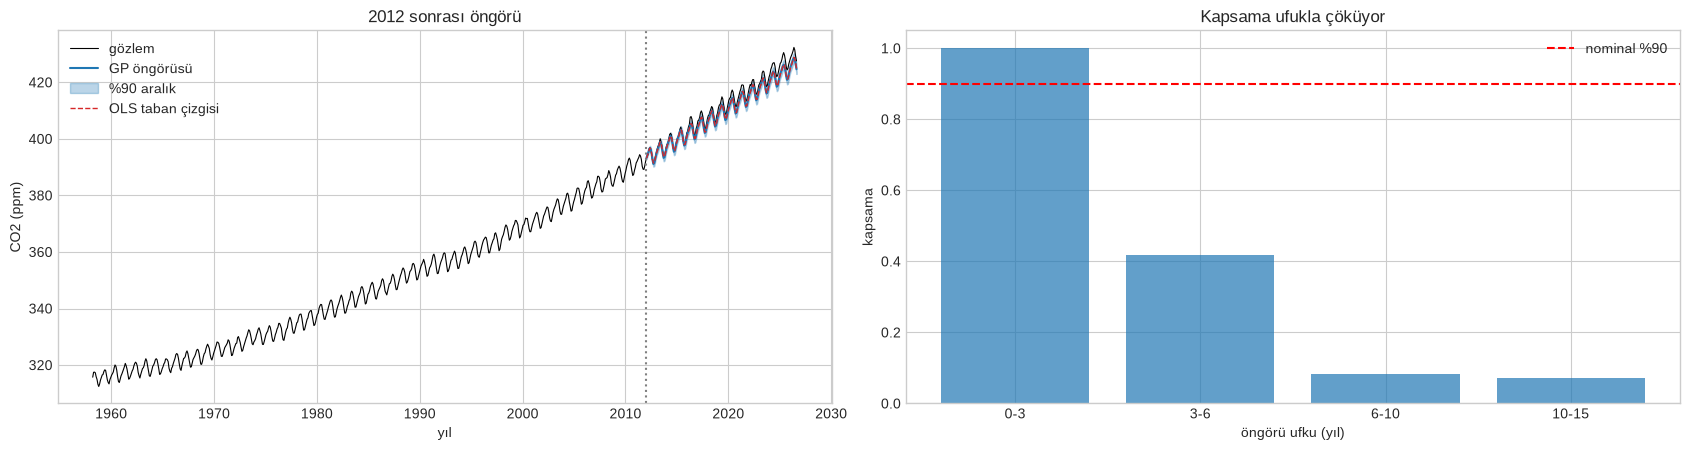

YORUM: ARADEĞERLEMEDE GP mükemmel (RMSE 0.42 ppm, kapsama ~nominal): yakın komşular ve mevsimsel yapı boşluğu dolduruyor. ÖNGÖRÜDE ise ilk 3 yılda iyi (kapsama %100), sonra sistematik yanlılık büyüyor: gözlem tahminin ÜSTÜNDE.
       Olası neden (ayrıca sınanmadı): gözlemler tahminin sürekli ÜSTÜNDE kaldığına göre CO2 artış hızı, 2012'ye kadar öğrenilen ikinci derece trendin öngördüğünden daha yüksek seyretti; çekirdekteki polinom trend bu değişimi önceden bilemez. GP'nin posterior sd'si yalnızca VARSAYILAN çekirdek ailesi içindeki belirsizliği ölçer — model yanlış özellendiğinde aralıklar aşırı özgüvenlidir.
       Genel ders: Bayesçi belirsizlik 'model doğruysa' geçerlidir. Aradeğerleme ve kısa ufuk güvenilir; uzun ufuk öngörüsünde çekirdek/trend yapısının kendisi sorgulanmalı, tek başına posterior aralığına güvenilmemeli. OLS taban çizgisi de benzer yanlılığı paylaşıyor, GP'nin ek getirisi kısa ufukta ve BELİRSİZLİK ÇIKTISINDA.


In [18]:
# (b) Öngörü: 2012'ye kadar eğit, 2012-2026 tahmin et
tr_b = co2[co2.dec < 2012]; te_b = co2[co2.dec >= 2012]
g_b, mu_b, nw_b = fit_gp(tr_b.dec.values, tr_b['mean'].values)
m_f, s_f = g_b.predict(scale_t(te_b.dec.values), return_std=True); m_f = m_f + mu_b; e_f = te_b['mean'].values - m_f
hz = te_b.dec.values - 2012

def feats(d): t_ = np.asarray(d) - 1990; return np.c_[np.ones_like(t_), t_, t_ ** 2, np.sin(2*np.pi*np.asarray(d)), np.cos(2*np.pi*np.asarray(d)), np.sin(4*np.pi*np.asarray(d)), np.cos(4*np.pi*np.asarray(d))]
w_ols = np.linalg.lstsq(feats(tr_b.dec.values), tr_b['mean'].values, rcond=None)[0]; e_o = te_b['mean'].values - feats(te_b.dec.values) @ w_ols
print(f"(b) ÖNGÖRÜ 2012-2026 ({len(te_b)} ay): GP RMSE = {np.sqrt(np.mean(e_f**2)):.3f} ppm | OLS(kuadratik+mevsim) RMSE = {np.sqrt(np.mean(e_o**2)):.3f} ppm | GP %90 kapsama = {np.mean(np.abs(e_f) < 1.645*s_f):.3f}")
rows = []
for lo, hi in [(0, 3), (3, 6), (6, 10), (10, 15)]:
    m = (hz >= lo) & (hz < hi)
    rows.append(dict(ufuk_yıl=f'{lo}-{hi}', n=int(m.sum()), GP_yanlılık=e_f[m].mean(), GP_RMSE=np.sqrt(np.mean(e_f[m] ** 2)), GP_ort_sd=s_f[m].mean(), GP_kapsama=np.mean(np.abs(e_f[m]) < 1.645 * s_f[m]), OLS_RMSE=np.sqrt(np.mean(e_o[m] ** 2))))
hor = pd.DataFrame(rows); print(hor.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(17, 4.6))
ax[0].plot(co2.dec, co2['mean'], c='k', lw=.8, label='gözlem'); ax[0].axvline(2012, c='gray', ls=':')
ax[0].plot(te_b.dec, m_f, 'C0', label='GP öngörüsü'); ax[0].fill_between(te_b.dec, m_f - 1.645 * s_f, m_f + 1.645 * s_f, color='C0', alpha=.3, label='%90 aralık')
ax[0].plot(te_b.dec, feats(te_b.dec.values) @ w_ols, 'C3--', lw=1, label='OLS taban çizgisi'); ax[0].set(xlabel='yıl', ylabel='CO2 (ppm)', title='2012 sonrası öngörü'); ax[0].legend()
ax[1].bar(range(len(hor)), hor.GP_kapsama, color='C0', alpha=.7); ax[1].axhline(.9, c='r', ls='--', label='nominal %90'); ax[1].set_xticks(range(len(hor))); ax[1].set_xticklabels(hor.ufuk_yıl); ax[1].set(xlabel='öngörü ufku (yıl)', ylabel='kapsama', ylim=(0, 1.05), title='Kapsama ufukla çöküyor'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"YORUM: ARADEĞERLEMEDE GP mükemmel (RMSE {np.sqrt(np.mean(e_i**2)):.2f} ppm, kapsama ~nominal): yakın komşular ve mevsimsel yapı boşluğu dolduruyor. ÖNGÖRÜDE ise ilk 3 yılda iyi (kapsama %{hor.GP_kapsama.iloc[0]*100:.0f}), sonra sistematik yanlılık büyüyor: gözlem tahminin ÜSTÜNDE.")
print("       Olası neden (ayrıca sınanmadı): gözlemler tahminin sürekli ÜSTÜNDE kaldığına göre CO2 artış hızı, 2012'ye kadar öğrenilen ikinci derece trendin öngördüğünden daha yüksek seyretti; çekirdekteki polinom trend bu değişimi önceden bilemez. GP'nin posterior sd'si yalnızca VARSAYILAN çekirdek ailesi içindeki belirsizliği ölçer — model yanlış özellendiğinde aralıklar aşırı özgüvenlidir.")
print("       Genel ders: Bayesçi belirsizlik 'model doğruysa' geçerlidir. Aradeğerleme ve kısa ufuk güvenilir; uzun ufuk öngörüsünde çekirdek/trend yapısının kendisi sorgulanmalı, tek başına posterior aralığına güvenilmemeli. OLS taban çizgisi de benzer yanlılığı paylaşıyor, GP'nin ek getirisi kısa ufukta ve BELİRSİZLİK ÇIKTISINDA.")

## Adım 6 · GP ile Bayesçi Optimizasyon (Expected Improvement)

Pahalı bir fonksiyonu az değerlendirmeyle **minimize** etme: $f(x)=\sin(3x)+x^2-0.7x$, $x\in[-1,2]$ (gerçekte "bir model eğit, doğrulama hatasını al" gibi pahalı bir çağrı olduğunu varsay). Strateji: 3 rastgele başlangıç + **9 adım**: her adımda GP'yi (Matérn 5/2) eldeki noktalara fit et, **EI** edinim fonksiyonunu maksimize eden noktayı değerlendir. Karşılaştırma: aynı bütçede (12 değerlendirme) **rastgele arama**, 20 tekrar.

Gerçek minimum: f(-0.359) = -0.5004


BO 20 tekrar: 9.0 s
 adım  BO ort. boşluk  BO medyan  Rastgele ort. boşluk  Rastgele medyan
    1          0.9477     0.9447                0.7777           0.7556
    2          0.5882     0.5945                0.5816           0.6251
    3          0.3849     0.2864                0.4306           0.3643
    4          0.3503     0.2043                0.2938           0.1067
    5          0.2961     0.1115                0.2891           0.1067
    6          0.2266     0.0464                0.1753           0.0279
    7          0.1306     0.0236                0.1249           0.0279
    8          0.0695     0.0025                0.1248           0.0279
    9          0.0438     0.0010                0.1043           0.0279
   10          0.0133     0.0002                0.0943           0.0279
   11          0.0015     0.0001                0.0596           0.0258
   12          0.0006     0.0001                0.0490           0.0140


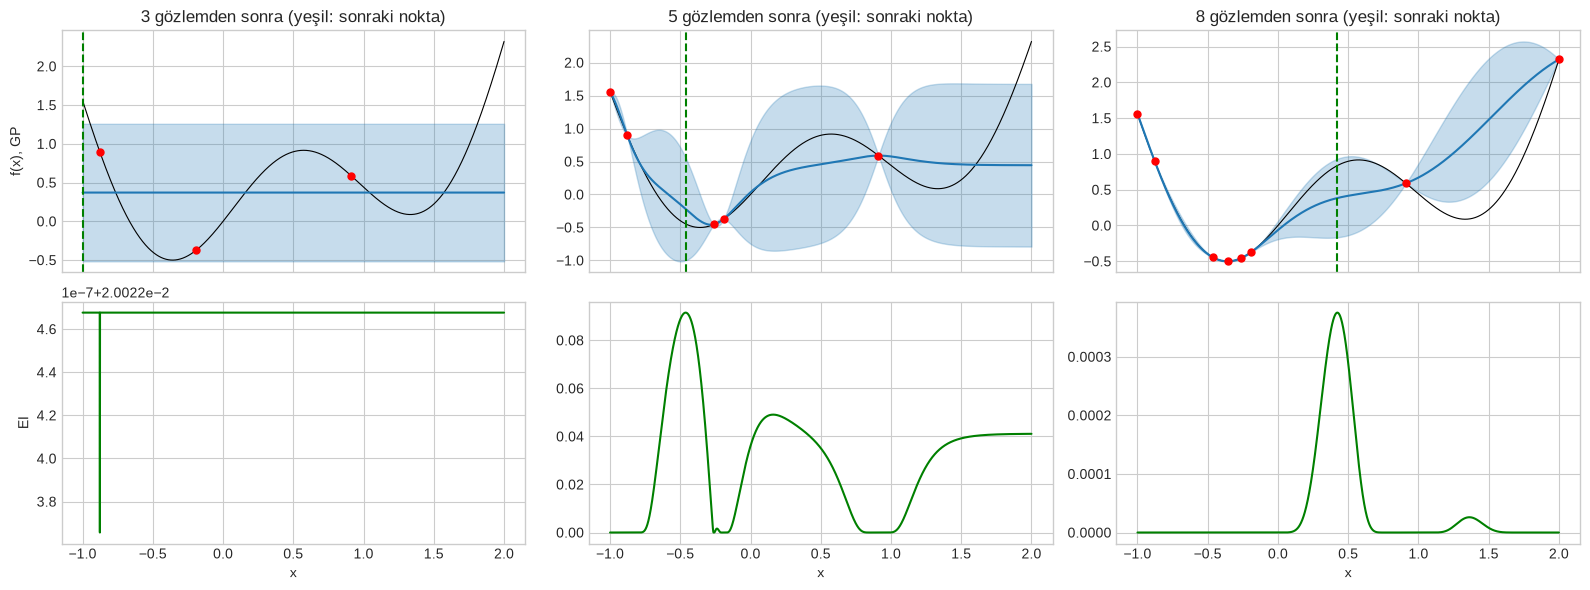

YORUM: 12 değerlendirmenin sonunda BO ortalama boşluğu 0.0006, rastgele arama 0.0490; BO'nun medyan boşluğu 0.00006.
       EI, belirsizliğin yüksek olduğu (keşif) ve ortalamanın düşük olduğu (sömürü) yerleri dengeliyor; üst grafikte yeşil dikey çizgiler önce belirsiz bölgelere, sonra gerçek minimuma yakınlaşıyor.
       İlk 3-4 adımda rastgele arama BO'dan iyi olabilir (BO henüz fonksiyonu öğreniyor); fark bütçe büyüdükçe belirginleşir. 13'teki Optuna/TPE aynı fikri farklı bir vekil modelle uygular.


In [19]:
from scipy.stats import norm
f_obj = lambda x: np.sin(3 * x) + x ** 2 - 0.7 * x
xg_bo = np.linspace(-1, 2, 3001); f_true_min = f_obj(xg_bo).min(); x_true_min = xg_bo[f_obj(xg_bo).argmin()]
print(f"Gerçek minimum: f({x_true_min:.3f}) = {f_true_min:.4f}")

def expected_improvement(mu, sd, best, xi=0.01):
    z = (best - mu - xi) / np.maximum(sd, 1e-12); return (best - mu - xi) * norm.cdf(z) + sd * norm.pdf(z)        # minimizasyon için EI

def run_bo(seed, n_init=3, n_iter=9, keep=False):
    rng = np.random.default_rng(seed); X = rng.uniform(-1, 2, n_init)[:, None]; y = f_obj(X[:, 0]); snaps = []
    for it in range(n_iter):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            g = GaussianProcessRegressor(C(1.0) * Matern(0.5, nu=2.5) + WhiteKernel(1e-6, (1e-8, 1e-2)), normalize_y=True, n_restarts_optimizer=2, random_state=0).fit(X, y)
        mu, sd = g.predict(xg_bo[:, None], return_std=True); ei = expected_improvement(mu, sd, y.min()); xn = xg_bo[np.argmax(ei)]
        if keep and it in (0, 2, 5): snaps.append((X.copy(), y.copy(), mu, sd, ei, xn))
        X = np.vstack([X, [[xn]]]); y = np.append(y, f_obj(xn))
    return (y, snaps) if keep else y

n_rep = 20
t0 = time.time(); bo_curves = np.array([np.minimum.accumulate(run_bo(s)) for s in range(n_rep)]); print(f"BO {n_rep} tekrar: {time.time()-t0:.1f} s")
rs_curves = np.array([np.minimum.accumulate(f_obj(np.random.default_rng(1000 + s).uniform(-1, 2, 12))) for s in range(n_rep)])
gap = lambda c: c - f_true_min
tab = pd.DataFrame({'adım': np.arange(1, 13), 'BO ort. boşluk': gap(bo_curves).mean(0), 'BO medyan': np.median(gap(bo_curves), 0), 'Rastgele ort. boşluk': gap(rs_curves).mean(0), 'Rastgele medyan': np.median(gap(rs_curves), 0)})
print(tab.round(4).to_string(index=False))

_, snaps = run_bo(0, keep=True)
fig, ax = plt.subplots(2, 3, figsize=(16, 6), sharex=True)
for j, (X_, y_, mu_, sd_, ei_, xn_) in enumerate(snaps):
    ax[0, j].plot(xg_bo, f_obj(xg_bo), 'k', lw=.8); ax[0, j].plot(xg_bo, mu_, 'C0'); ax[0, j].fill_between(xg_bo, mu_ - 1.645 * sd_, mu_ + 1.645 * sd_, color='C0', alpha=.25)
    ax[0, j].scatter(X_[:, 0], y_, c='r', zorder=3, s=25); ax[0, j].axvline(xn_, c='g', ls='--'); ax[0, j].set_title(f'{len(X_)} gözlemden sonra (yeşil: sonraki nokta)')
    ax[1, j].plot(xg_bo, ei_, 'g'); ax[1, j].set(xlabel='x'); ax[0, 0].set_ylabel('f(x), GP'); ax[1, 0].set_ylabel('EI')
plt.tight_layout(); plt.show()
print(f"YORUM: 12 değerlendirmenin sonunda BO ortalama boşluğu {gap(bo_curves)[:,-1].mean():.4f}, rastgele arama {gap(rs_curves)[:,-1].mean():.4f}; BO'nun medyan boşluğu {np.median(gap(bo_curves)[:,-1]):.5f}.")
print("       EI, belirsizliğin yüksek olduğu (keşif) ve ortalamanın düşük olduğu (sömürü) yerleri dengeliyor; üst grafikte yeşil dikey çizgiler önce belirsiz bölgelere, sonra gerçek minimuma yakınlaşıyor.")
print("       İlk 3-4 adımda rastgele arama BO'dan iyi olabilir (BO henüz fonksiyonu öğreniyor); fark bütçe büyüdükçe belirginleşir. 13'teki Optuna/TPE aynı fikri farklı bir vekil modelle uygular.")

# 📊 R Uygulaması

Bayesçi modelleme R'da **Stan** üzerinden yapılır; `rstanarm::stan_glm` formül arayüzüyle (lm/glm gibi) HMC/NUTS posterior örnekleri üretir (Gabry, Goodrich ve ark.). Proje kararı gereği (bkz. [[notebook_style_convention]]) R bölümü kısa: önce Python referans sayıları, ardından 1 hücrede aynı iki modeli `stan_glm` ile kuruyoruz (Howell yetişkin boy~kilo; Wells lojistik, $\mathcal{N}(0,1)$ eğim prior'u).

In [20]:
# Referans sayılar (Python): R/Stan çıktısıyla karşılaştırmak için
sd_h = np.sqrt(np.diag(be.S))
print(f"Howell yetişkin (merkezli kilo): eğim = {be.m[1]:.3f} ± {sd_h[1]:.3f} cm/kg | gürültü sd = {1/np.sqrt(be.beta):.2f} cm")
print("Wells (MAP / Laplace sd):"); print(pd.DataFrame({'MAP': w_map, 'Laplace sd': np.sqrt(np.diag(Sig_map))}, index=names).round(3).to_string())
print("R'da `posterior_interval(fit, prob = 0.9)` ile eğim için yaklaşık aynı ±1,645 sd aralıkları beklenir; Stan'in prior'ı farklıysa küçük sapmalar normaldir.")

Howell yetişkin (merkezli kilo): eğim = 0.901 ± 0.042 cm/kg | gürültü sd = 5.09 cm
Wells (MAP / Laplace sd):
                MAP  Laplace sd
kesişim       0.388       0.051
arsenik       0.465       0.042
mesafe(100m) -0.886       0.104
eğitim(4y)    0.169       0.038
topluluk     -0.124       0.077
R'da `posterior_interval(fit, prob = 0.9)` ile eğim için yaklaşık aynı ±1,645 sd aralıkları beklenir; Stan'in prior'ı farklıysa küçük sapmalar normaldir.


In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R -w 900 -h 400
# install.packages("rstanarm")  # ilk çalıştırmada gerekir (Stan derleyicisi ister)
library(rstanarm)
howell <- read.csv("data/howell1.csv", sep = ";"); adult <- subset(howell, age >= 18)
adult$wc <- adult$weight - mean(adult$weight)
fit_h <- stan_glm(height ~ wc, data = adult, family = gaussian(), prior = normal(0, 1, autoscale = FALSE), refresh = 0, seed = 1)
print(round(posterior_interval(fit_h, prob = 0.9), 3))

wells <- read.csv("data/wells.csv"); wells$y <- as.integer(wells$switch == "yes")
wells$ars <- wells$arsenic - mean(wells$arsenic); wells$dist100 <- (wells$distance - mean(wells$distance)) / 100
wells$edu4 <- (wells$education - mean(wells$education)) / 4; wells$assoc <- as.integer(wells$association == "yes")
fit_w <- stan_glm(y ~ ars + dist100 + edu4 + assoc, data = wells, family = binomial(),
                  prior = normal(0, 1, autoscale = FALSE), prior_intercept = normal(0, 5, autoscale = FALSE), refresh = 0, seed = 1)
print(round(cbind(mean = coef(fit_w), sd = se(fit_w)), 3))
plot(fit_w, pars = c("ars", "dist100", "edu4", "assoc"))

# 🗄️ SQL Uygulaması (DuckDB)

Bayesçi modellerin bazı parçaları **yeterli istatistiklerle** (toplamlarla) hesaplanır ve SQL'e doğal oturur. Proje kararı gereği (bkz. [[notebook_style_convention]]) iki kısa hücre:

1. **Bayesçi doğrusal regresyon posterior'u:** $A=\alpha I+\beta\Phi^\top\Phi$ yalnızca $n,\sum x,\sum x^2,\sum y,\sum xy$ ile kurulur; $2\times2$ ters kapalı formda. Veri ambarında *ham veriyi çekmeden* posterior + öngörü hesaplanır. Python sonucuyla karşılaştırıyoruz.
2. **GP ortalama öngörüsü:** $\mu(x_*)=\sum_i k(x_*,x_i)\,\alpha_i$ — eğitim noktaları ile test noktalarının `CROSS JOIN`'i; $\alpha=K_y^{-1}y$ Python'da hesaplanır, SQL yalnızca çekirdek toplamını yapar.

In [23]:
import duckdb
con = duckdb.connect()

# --- SQL-1: Bayesçi doğrusal regresyon (Howell yetişkin, merkezli) — yalnızca toplamlarla ---
con.register('h', pd.DataFrame({'x': xc, 'y': yc}))
al_, be_ = be.alpha, be.beta                            # kanıt-maksimizasyonundan gelen kesinlikler (Python'dan parametre olarak geçiyor)
sql_bayes = con.execute(f"""
WITH ag AS (SELECT COUNT(*) AS n, SUM(x) AS sx, SUM(x*x) AS sxx, SUM(y) AS sy, SUM(x*y) AS sxy FROM h),
A AS (SELECT {al_} + {be_}*n AS a11, {be_}*sx AS a12, {al_} + {be_}*sxx AS a22, {be_}*sy AS r1, {be_}*sxy AS r2 FROM ag),
P AS (SELECT a11, a12, a22, a11*a22 - a12*a12 AS det, r1, r2 FROM A),
post AS (SELECT a22/det AS s00, -a12/det AS s01, a11/det AS s11,
                (a22*r1 - a12*r2)/det AS m0, (-a12*r1 + a11*r2)/det AS m1 FROM P)
SELECT xs AS x_star, m0 + m1*xs AS mean, SQRT(s00 + 2*s01*xs + s11*xs*xs + 1.0/{be_}) AS pred_sd, m0, m1
FROM post, (VALUES (-10.0), (0.0), (10.0)) t(xs) ORDER BY xs
""").df()
mu_py, sd_py = be.predict(np.c_[np.ones(3), [-10., 0., 10.]])
print(sql_bayes[['x_star', 'mean', 'pred_sd']].round(5).to_string(index=False))
print(f"Python: ortalama {mu_py.round(5)} | sd {sd_py.round(5)}")
print(f"SQL ile Python maks. fark: ortalama {np.abs(sql_bayes['mean'].values - mu_py).max():.1e}, sd {np.abs(sql_bayes.pred_sd.values - sd_py).max():.1e}")
print(f"YORUM: SQL, ham 352 satıra yalnızca BİR geçişle (5 toplam) bakıp posterior ortalaması (m1={sql_bayes.m1.iloc[0]:.4f}) ve öngörü sd'sini Python'la makine hassasiyetinde üretiyor. Bu, 'yeterli istatistik' fikrinin pratik karşılığı: yeni gelen veri yalnızca toplamları günceller (akan veride Bayes güncellemesi).")

# --- SQL-2: GP ortalama öngörüsü — CROSS JOIN ile çekirdek toplamı ---
ell_, sf2_, sn2_ = np.exp(theta_hat)
Kmat = rbf_kernel(xm, xm, ell_, sf2_) + (sn2_ + 1e-10) * np.eye(len(xm)); alpha_gp = np.linalg.solve(Kmat, yz_m)       # alpha = K_y^{-1} y
con.register('gp_train', pd.DataFrame({'x': xm, 'a': alpha_gp}))
grid_sql = np.array([5., 14., 20., 25., 35., 50.]); con.register('grid', pd.DataFrame({'xs': grid_sql}))
gp_sql = con.execute(f"""
SELECT g.xs, SUM({sf2_} * EXP(-0.5 * (g.xs - t.x)*(g.xs - t.x) / {ell_**2}) * t.a) AS mean_z
FROM grid g CROSS JOIN gp_train t GROUP BY g.xs ORDER BY g.xs
""").df()
mu_gp, _ = gp_predict(theta_hat, xm, yz_m, grid_sql)
print("\n", pd.DataFrame({'ms': grid_sql, 'SQL ort. (z)': gp_sql.mean_z.values, 'Python ort. (z)': mu_gp, 'SQL ivme (g)': gp_sql.mean_z.values * y_std + y_mean}).round(4).to_string(index=False))
print(f"SQL ile Python maks. fark = {np.abs(gp_sql.mean_z.values - mu_gp).max():.1e}")
print("YORUM: GP ortalaması, eğitim noktalarında çekirdek ağırlıklı bir toplam; SQL'de 133 x 6 satırlık CROSS JOIN yeterli. Öngörü VARYANSI ise K_y^{-1}'in tamamını ister (n x n matris) — bu yüzden veri tabanında yalnızca ortalamayı yapıp varyansı Python'da bırakıyoruz.")

 x_star     mean  pred_sd
  -10.0 -9.01397  5.10876
    0.0 -0.00000  5.09150
   10.0  9.01397  5.10876
Python: ortalama [-9.01397 -0.       9.01397] | sd [5.10876 5.0915  5.10876]
SQL ile Python maks. fark: ortalama 2.1e-14, sd 0.0e+00
YORUM: SQL, ham 352 satıra yalnızca BİR geçişle (5 toplam) bakıp posterior ortalaması (m1=0.9014) ve öngörü sd'sini Python'la makine hassasiyetinde üretiyor. Bu, 'yeterli istatistik' fikrinin pratik karşılığı: yeni gelen veri yalnızca toplamları günceller (akan veride Bayes güncellemesi).

   ms  SQL ort. (z)  Python ort. (z)  SQL ivme (g)
 5.0        0.4379           0.4379       -4.4663
14.0        0.2877           0.2877      -11.6962
20.0       -1.8500          -1.8500     -114.6051
25.0       -0.8981          -0.8981      -68.7803
35.0        0.9895           0.9895       22.0868
50.0        0.3548           0.3548       -8.4665
SQL ile Python maks. fark = 3.8e-15
YORUM: GP ortalaması, eğitim noktalarında çekirdek ağırlıklı bir toplam; SQL'de 133 x

## ✏️ Egzersizler

Her egzersizde kod hücresi **boş**; içinde `# TODO` adımları var — sırayla uygula. Hepsi bu notebook'ta tanımlı hazır fonksiyonlarla (`BayesLinReg`, `logistic_map`, `run_chains`, `metropolis`, `gp_predict` ...) ve sklearn'in hazır modelleriyle çözülebilir; sıfırdan yeni algoritma yazmak gerekmiyor.

**E1.** Para atışında **prior duyarlılığı:** 10 atışta 7 yazı (Adım 1) ve 100 atışta 70 yazı için dört prior'u karşılaştır: $\mathrm{Beta}(1,1)$, $\mathrm{Beta}(2,2)$, $\mathrm{Beta}(20,20)$ ve $\mathrm{Beta}(1,9)$ ("yazı nadirdir" inancı). Posterior ortalaması, %90 aralık ve $P(\theta>0.5)$ tablosunu çıkar. Veri 10 kat artınca prior'ların farkı ne oluyor? Hangi prior'un log-kanıtı en yüksek?

In [24]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Kapalı form: posterior $\mathrm{Beta}(a+k,\ b+n-k)$; `from scipy.stats import beta, betaln`. İki
#         veri kümesi için `(k, n) in [(7, 10), (70, 100)]` döngüsü kur.
# TODO 2: Her prior $(a,b)$ için `post = beta(a + k, b + n - k)`; `post.mean()`, `post.interval(0.90)` ve
#         `post.sf(0.5)` (= $P(\theta>0.5)$) değerlerini sakla.
# TODO 3: Log-kanıt: `betaln(a + k, b + n - k) - betaln(a, b)` (binom katsayısı tüm prior'larda ortak,
#         atlayabilirsin).
# TODO 4: Sonuçları iki DataFrame'de (n=10 ve n=100) göster; sütunlar: ortalama, aralık alt/üst,
#         $P(\theta>0.5)$, log-kanıt.
# TODO 5: Yorum: prior'lar arası ortalama farkı n=10'dan n=100'e küçüldü mü? (Prior'un 'sanal gözlem
#         sayısı' $a+b$ ile veri sayısı $n$'i kıyasla.) Beta(1,9) 100 atışta hâlâ kanıt kaybediyor mu?

**E2.** Howell1'in **tüm** verisinde (çocuklar dahil) boy~kilo eğrisi için Legendre polinom derecesini (1–8) `sklearn.linear_model.BayesianRidge` ve `ARDRegression` ile karşılaştır. Adım 2'deki gibi 5-katlı CV RMSE (cm) ve (BayesianRidge için) `compute_score=True` log-kanıtı tablosu çıkar. ARD, gereksiz yüksek derece katsayılarını gerçekten sıfıra yakın çekiyor mu?

In [25]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `xs_all` (kilo, [-1,1]'e ölçekli), `y_all` (boy), `yz` (standartlaşmış boy), `ysd_`.
#         Tasarım matrisi: `Phi = Leg.legvander(xs_all, d)` (d = derece).
# TODO 2: Döngü `for d in range(1, 9):` içinde `BayesianRidge(fit_intercept=False, compute_score=True)` ve
#         `ARDRegression(fit_intercept=False)` kur (legvander zaten sabit sütunu içerir).
# TODO 3: CV: `cross_val_score(model, Phi, yz, cv=KFold(5, shuffle=True, random_state=0),
#         scoring='neg_mean_squared_error')`; RMSE (cm) = `np.sqrt(-skor.mean()) * ysd_`. (`from
#         sklearn.model_selection import cross_val_score`.)
# TODO 4: Tüm veriye fit et; BayesianRidge için `m.scores_[-1]` log-kanıttır. ARD için
#         `np.sum(np.abs(m.coef_) < 1e-3)` ile 'sıfırlanan' katsayıları say.
# TODO 5: Tablo: derece, CV RMSE (iki model), log-kanıt, ARD'nin sıfırladığı katsayı sayısı. Yorum: kanıt
#         ve CV aynı dereceyi mi seçiyor? Aralarındaki fark istatistiksel olarak anlamlı mı (CV katlar
#         arası sd ile kıyasla)?

**E3.** Wells'te **prior genişliği** sınavı: eğim prior sd'sini $\sigma\in\{0.1, 0.3, 1, 3, 10, 100\}$ yap (kesişim sd=5 sabit). Küçük eğitim kümesinde (n=60) ve büyük kümede (n=2000) test log-loss'unu karşılaştır; her n için 20 rastgele bölme ortalaması al. Küçük n'de hangi $\sigma$ en iyi? $\sigma=100$ (neredeyse prior'suz) MLE'ye ne kadar yaklaşıyor?

In [26]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `Xw`, `y_w`, `logistic_map(X, y, alpha_vec)` (MAP katsayıları döner: ilk çıktı). Prior
#         kesinliği `alpha_vec = np.r_[1/25, np.full(4, 1/sigma**2)]`.
# TODO 2: Her tekrar için `rng.permutation(len(y_w))`; ilk n satır eğitim, kalan **tüm** satırlar test
#         (n=2000 için test = 1020 satır).
# TODO 3: Test log-loss: `p = expit(X_te @ w)`; `-np.mean(y_te*np.log(p) + (1-y_te)*np.log(1-p))`
#         (`sklearn.metrics.log_loss` da olur). `p`'yi 1e-12 ile kırp.
# TODO 4: İç içe döngü: n ∈ [60, 2000], σ ∈ listede, rep ∈ 20 → ortalama ve standart hata tablosu (satır
#         σ, sütun n). Aynı tekrarlarda aynı bölmeyi kullan ki σ'lar eşleşik kıyaslansın.
# TODO 5: Yorum: en iyi σ n=60'ta ile n=2000'de aynı mı? Küçük n'de σ=100 sonucu 'MLE benzeri' kötü mü?
#         (Bölmelerde MLE ayrışma/ayırma problemine dikkat: büyük w'lar log-loss'u şişirir.)

**E4.** Metropolis **öneri ölçeği** ayarı: Wells posterior'unda (`run_chains`) öneri ölçeğini $s\in\{0.05, 0.3, 1.0, 2.38/\sqrt{5}, 3, 10\}$ yap. Her biri için kabul oranı, `arsenik` katsayısının ESS'i ve R-hat'ı tablo yap. ESS'i en yükseğe çıkaran ölçekte kabul oranı kaç? "Optimal kabul oranı ~%23" kuralı tutuyor mu?

In [27]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `run_chains(Xw, y_w, alpha_vec, w_map, Sig_map, n=6000, burn=1500, scale=s)` →
#         `(zincirler (4, n, 5), kabul oranları)` döner. (Süre için n'i küçük tut.)
# TODO 2: Döngü `for s in [0.05, 0.3, 1.0, 2.38/np.sqrt(5), 3, 10]:`; `ch, acc = run_chains(...)`; kabul
#         oranı = `acc.mean()`.
# TODO 3: Arsenik katsayısı = sütun 1: `ess(ch[:, :, 1])` ve `rhat(ch[:, :, 1])` (ikisi de notebook'ta
#         tanımlı).
# TODO 4: Birim zamanda verim: `ESS / süre`. Süreyi `time.perf_counter()` ile ölç (öneri ölçeğinden
#         bağımsız yaklaşık aynı olmalı).
# TODO 5: ESS'e karşı kabul oranını çiz (`plt.plot`, log-x). Yorum: çok küçük ölçekte (yüksek kabul) ve
#         çok büyük ölçekte (düşük kabul) ESS neden çöküyor? Önerinin `Sig_map` ile şekillendirilmesi
#         (chol) neyi kolaylaştırdı?

**E5.** Mauna Loa CO₂ çekirdeğinde **bileşen ablasyonu:** `k_co2`'yu üç bileşenine ayır (uzun vadeli trend `C·DotProduct²`, mevsimsel `C·RBF·ExpSineSquared`, orta vadeli `C·RBF`) ve her seferinde birini çıkar. Adım 5(a) aradeğerleme kurulumunda (`tr_a`, `te_a`) log marjinal olabilirlik ve test RMSE tablosu çıkar. Hangi bileşen çıkarılınca performans en çok düşüyor?

In [28]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Hazır: `tr_a`, `te_a`, `scale_t`, `k_co2`'nun parçaları (kodunu yukarıdan kopyala): `k_trend =
#         C(100.0**2,(1e-2,1e8))*DotProduct(1.0,'fixed')**2`, `k_seas =
#         C(2.0**2)*RBF(1.0)*ExpSineSquared(1.0,0.05,periodicity_bounds='fixed')`, `k_mid =
#         C(0.5**2)*RBF(0.2)`, `k_noise = WhiteKernel(0.1)`.
# TODO 2: Dört model sözlüğü: tam (`k_trend+k_seas+k_mid+k_noise`), trendsiz, mevsimsiz, orta vadesiz
#         (gürültü hep var).
# TODO 3: Her model için `GaussianProcessRegressor(k, n_restarts_optimizer=0,
#         random_state=0).fit(scale_t(tr_a.dec.values), tr_a['mean'].values - mu)`; `mu =
#         tr_a['mean'].mean()`. `warnings.catch_warnings(record=True)` ile uyarıları say.
# TODO 4: `gp.log_marginal_likelihood_value_` ve test RMSE'si (`gp.predict(scale_t(te_a.dec.values)) + mu`
#         ile `te_a['mean']` farkı) kaydet.
# TODO 5: Yorum: trendsiz modelde ne oluyor (stasyoner çekirdeğin ortalamaya dönmesi)? Log-kanıt
#         sıralaması RMSE sıralamasıyla uyuşuyor mu?

**E6.** Bayesçi optimizasyonda **edinim fonksiyonu** karşılaştırması: Expected Improvement (EI), **Lower Confidence Bound** ($\mathrm{LCB}=\mu-\kappa\sigma$, $\kappa\in\{0.5, 2\}$) ve rastgele arama; hepsini aynı bütçeyle (3 başlangıç + 9 adım), 20 tekrarla koştur. 12. adımda ortalama/medyan boşluk ve 6. adımdaki boşluk tablosu çıkar. Hangisi en hızlı yaklaşıyor?

In [29]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: `run_bo` fonksiyonunu kopyala ve edinim kısmını parametrik yap: `acq='ei'` ise `ei =
#         expected_improvement(mu, sd, y.min())`, `acq='lcb'` ise `score = -(mu - kappa*sd)`. Sonraki
#         nokta `xg_bo[np.argmax(score)]`.
# TODO 2: Dört yapılandırma: EI, LCB(κ=0.5), LCB(κ=2), rastgele (`bo_curves`/`rs_curves` kurulumundaki
#         gibi).
# TODO 3: Her yapılandırma için 20 tekrarda `np.minimum.accumulate(y)` eğrisi al; boşluk = eğri −
#         `f_true_min`.
# TODO 4: Tablo: adım 6 ve 12 için ortalama ve medyan boşluk. `plt.semilogy` ile ortalama boşluk
#         eğrilerini çiz.
# TODO 5: Yorum: κ büyükken (keşif ağırlıklı) ne olur, küçükken (sömürü ağırlıklı) yerel minimuma takılma
#         görülüyor mu? EI hangi taraf?

## 📚 Kaynaklar

| Kaynak | Tür | Bu notebook'ta nerede |
|---|---|---|
| [Bishop (2006) — *Pattern Recognition and Machine Learning*, Bölüm 3 (Bayesçi doğrusal regresyon, kanıt), 4.4 (Laplace), 6.4 (GP)](https://www.microsoft.com/en-us/research/publication/pattern-recognition-machine-learning/) | Kitap (yayıncı sayfası) | Teori: posterior, kanıt, Laplace, GP formülleri |
| [Rasmussen & Williams (2006) — *Gaussian Processes for Machine Learning*](https://gaussianprocess.org/gpml/) | Kitap (ücretsiz PDF) | Bölüm 2 (GP regresyon), 4–5 (çekirdekler, model seçimi), 5.4.2 (kapalı form LOO) |
| [McElreath — *Statistical Rethinking*](https://xcelab.net/rm/) · [Howell1 verisi (GitHub)](https://github.com/rmcelreath/rethinking/blob/master/data/Howell1.csv) | Kitap + veri | Adım 2: Howell1 (Dobe !Kung, 544 kişi) |
| [Gelman ve ark. — *Bayesian Data Analysis* (BDA3)](https://sites.stat.columbia.edu/gelman/book/) | Kitap (yazar sayfası) | Beta–Binom, MCMC, tanılar |
| [Gelman & Hill (2007) — *Data Analysis Using Regression and Multilevel/Hierarchical Models*](https://sites.stat.columbia.edu/gelman/arm/) | Kitap + veri | Adım 3: Wells (Bangladeş kuyu arseniği) |
| [MacKay (1992) — "Bayesian Interpolation", *Neural Computation* 4(3)](https://doi.org/10.1162/neco.1992.4.3.415) | Makale | Kanıt maksimizasyonu, etkin parametre sayısı $\gamma$ |
| [Tipping (2001) — "Sparse Bayesian Learning and the Relevance Vector Machine", *JMLR* 1](https://www.jmlr.org/papers/v1/tipping01a.html) | Makale | ARD / seyrek Bayes (E2) |
| [Metropolis ve ark. (1953), *J. Chem. Phys.*](https://doi.org/10.1063/1.1699114) · [Hastings (1970), *Biometrika*](https://doi.org/10.1093/biomet/57.1.97) | Makale | MH algoritması |
| [Gelman & Rubin (1992) — "Inference from Iterative Simulation Using Multiple Sequences", *Statistical Science*](https://doi.org/10.1214/ss/1177011136) · [Vehtari ve ark. (2021) — "Rank-normalization, folding, and localization: an improved $\hat R$", *Bayesian Analysis*](https://doi.org/10.1214/20-BA1221) | Makale | $\hat R$ (bölünmüş), ESS |
| [Shahriari ve ark. (2016) — "Taking the Human Out of the Loop: A Review of Bayesian Optimization", *Proc. IEEE*](https://doi.org/10.1109/JPROC.2015.2494218) · [Snoek, Larochelle, Adams (2012), arXiv:1206.2944](https://arxiv.org/abs/1206.2944) | Makale | Adım 6: EI, BO |
| [Silverman (1985), *JRSS B* 47(1) — mcycle verisinin kaynağı](https://doi.org/10.1111/j.2517-6161.1985.tb01327.x) · [Rdatasets: MASS/mcycle](https://vincentarelbundock.github.io/Rdatasets/) | Makale + veri | Adım 4: motosiklet çarpışması ivme ölçümleri (133 satır) |
| [NOAA GML — Mauna Loa CO₂](https://gml.noaa.gov/ccgg/trends/) · [Keeling eğrisi — Scripps](https://keelingcurve.ucsd.edu/) · [datasets/co2-ppm (GitHub kopyası)](https://github.com/datasets/co2-ppm) | Veri | Adım 5: aylık CO₂ (1958–), bu CSV'de ay sayısı çıktıda yazılı |
| [Carpenter ve ark. (2017) — "Stan: A Probabilistic Programming Language", *JSS* 76(1)](https://doi.org/10.18637/jss.v076.i01) · [rstanarm](https://mc-stan.org/rstanarm/) | Makale + R paketi | R bölümü: `stan_glm` |
| [Salvatier, Wiecki, Fonnesbeck (2016) — "Probabilistic programming in Python using PyMC3", *PeerJ CS*](https://doi.org/10.7717/peerj-cs.55) · [Gardner ve ark. (2018) — GPyTorch, arXiv:1809.11165](https://arxiv.org/abs/1809.11165) | Makale | Ölçeklenebilir Python alternatifleri (bu notebook'ta çalıştırılmadı) |
| [scikit-learn — Gaussian Processes](https://scikit-learn.org/stable/modules/gaussian_process.html) · [Bayesian Regression (BayesianRidge, ARD)](https://scikit-learn.org/stable/modules/linear_model.html#bayesian-regression) | Dokümantasyon | Doğrulama referansları |